# Density forecasts with `forecast_evaluation`

This notebook covers the density forecast workflow from data to evaluation, in three parts:

1. **Working with density data**: the `DensityForecastData` data contract, adding forecasts, quantile crossing, filtering, plotting, sampling and conversion to point forecasts.
2. **Fitting and evaluating densities on a known answer**: synthetic forecasts where one source is correct and one is too narrow, to show what the calibration tests, scores and sharpness measures detect.
3. **End to end with OPERA**: real-time BVAR density forecasts of UK CPI inflation from the OPERA `bvar` and `forecast_realtime` packages, fitted and evaluated with the metrics used in the Bank's Macro Technical Paper (MTP) on density forecast evaluation.

Parts 1 and 2 need only `forecast_evaluation`. Part 3 also needs `bvar` and `forecast_realtime` (installed with `opera-eco`) and takes a few minutes to run.

In [22]:
import warnings

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

import forecast_evaluation as fe

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

## Part 1: Working with density data

### The data contract

`DensityForecastData` extends `ForecastData`. A density forecast is a set of rows, one per quantile level, with the point-forecast columns plus `quantile`:

| Column | Meaning |
|---|---|
| `date` | target period (snapped to the period end) |
| `vintage_date` | when the forecast was made |
| `variable`, `frequency`, `metric` | must match the outturns; `metric` is `levels`, `pop` or `yoy` (default `levels`) |
| `source` | forecaster or model; with any `extra_ids`, forms `unique_id` |
| `forecast_horizon` | declared horizon (evaluation uses target minus vintage) |
| `quantile` | probability level in [0, 1] |
| `value` | the quantile of the predictive distribution, finite |

Outturns are added first, so densities can be validated against them. The package ships sample data in this format.

In [23]:
from forecast_evaluation.data.sample_data import create_sample_density_forecasts

density_df = create_sample_density_forecasts()
density_data = fe.DensityForecastData(outturns_data=fe.create_sample_outturns(), forecasts_data=density_df)

forecasts = density_data.density_forecasts
print("density rows:", len(forecasts), "| quantile levels:", forecasts["quantile"].nunique())
print("variables:", forecasts["variable"].unique().tolist(), "| sources:", forecasts["source"].unique().tolist())
print("id columns:", density_data.id_columns)
forecasts.head()

\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\ForecastData.py:180: UserWarning: Outturns input has no 'metric' column; assigning metric='levels' to all rows.
  self.add_outturns(outturns_data, metric=metric)
\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:195: UserWarning: Forecasts input has no 'metric' column; assigning metric='levels' to all rows.
  df = self._validate_new_forecasts(


density rows: 650 | quantile levels: 50
variables: ['gdpkp'] | sources: ['mpr2']
id columns: ['source']


,date,variable,vintage_date,source,frequency,quantile,value,forecast_horizon,metric,target_minus_vintage,unique_id
0,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0.01,113.813094,0,levels,0,mpr2
1,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0.03,114.058037,0,levels,0,mpr2
2,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0.05,114.162953,0,levels,0,mpr2
3,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0.07,114.251326,0,levels,0,mpr2
4,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0.09,114.316441,0,levels,0,mpr2


In [11]:
print(density_data.outturns.groupby(["variable", "metric"]).size().unstack())

metric    levels  pop  yoy
variable                  
cpisa         13   12    9
gdpkp         13   12    9


In [20]:
# Print summary of density data 
density_data.summary()


DATA SUMMARY

[OUTTURNS]
  Number of variables: 2
  Variables: cpisa, gdpkp

  Variable | Freq | Date                     | Vintage                 
  ---------------------------------------------------------------------
  cpisa    | Q    | 2022-03-31 to 2025-03-31 | 2025-09-30 to 2025-09-30
  gdpkp    | Q    | 2022-03-31 to 2025-03-31 | 2025-09-30 to 2025-09-30
  ---------------------------------------------------------------------

[FORECASTS] No point forecasts loaded (density forecasts are loaded: see [DENSITY FORECASTS])

[DENSITY FORECASTS]
  Number of variables: 1
  Variables: gdpkp

  Number of sources: 1
  Sources: mpr2

  mpr2
  Variable | Metric | Freq | Date                     | Vintage                  | Horizon 
  -----------------------------------------------------------------------------------------
  gdpkp    | levels | Q    | 2025-12-31 to 2028-12-31 | 2025-12-31 to 2025-12-31 | 0 to 12 
  ----------------------------------------------------------------------------

### Adding forecasts to an existing object

Outturns must be present before density forecasts are added. `add_density_forecasts` validates and appends further densities, for example from another source.

In [12]:
density_data_2 = fe.DensityForecastData(outturns_data=fe.create_sample_outturns())
print("before:", density_data_2.density_forecasts.shape)
density_data_2.add_density_forecasts(density_df)
print("after: ", density_data_2.density_forecasts.shape)

\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\ForecastData.py:180: UserWarning: Outturns input has no 'metric' column; assigning metric='levels' to all rows.
  self.add_outturns(outturns_data, metric=metric)


before: (0, 0)


\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:195: UserWarning: Forecasts input has no 'metric' column; assigning metric='levels' to all rows.
  df = self._validate_new_forecasts(


after:  (650, 11)


### Quantile crossing

A valid density has quantile values that do not decrease with the level. `crossing` sets what happens otherwise: `"rearrange"` (default) sorts the values within each crossed density and warns once per call, `"error"` rejects the input, and `"ignore"` keeps it as supplied. Equal adjacent values are valid.

In [17]:
# One density with two quantile values swapped, so the quantile function decreases.
key = ["date", "vintage_date", "variable", "source"]
crossed = density_df[density_df.groupby(key).ngroup() == 0].sort_values("quantile").copy()
value_col = crossed.columns.get_loc("value")
crossed.iloc[[1, -2], value_col] = crossed["value"].iloc[[-2, 1]].to_numpy()

try:
    fe.DensityForecastData(outturns_data=fe.create_sample_outturns(), forecasts_data=crossed, crossing="error")
except ValueError as err:
    print("crossing='error'    :", err)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    repaired = fe.DensityForecastData(outturns_data=fe.create_sample_outturns(), forecasts_data=crossed)
print("crossing='rearrange':", [str(w.message) for w in caught if str(w.message).startswith("Rearranged")])
values = repaired.density_forecasts.sort_values("quantile")["value"]
print("non-decreasing after rearranging:", bool((values.diff().dropna() >= 0).all()))

\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\ForecastData.py:180: UserWarning: Outturns input has no 'metric' column; assigning metric='levels' to all rows.
  self.add_outturns(outturns_data, metric=metric)
\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:195: UserWarning: Forecasts input has no 'metric' column; assigning metric='levels' to all rows.
  df = self._validate_new_forecasts(


crossing='error'    : 1 of 1 densities have values that are not non-decreasing in quantile; examples: date=2025-12-31, variable=gdpkp, vintage_date=2025-12-31, source=mpr2, frequency=Q, forecast_horizon=0, metric=levels, target_minus_vintage=0, unique_id=mpr2.
crossing='rearrange': ['Rearranged 1 of 1 densities because values were not non-decreasing in quantile (largest absolute change 1.88474); example key: date=2025-12-31, variable=gdpkp, vintage_date=2025-12-31, source=mpr2, frequency=Q, forecast_horizon=0, metric=levels, target_minus_vintage=0, unique_id=mpr2. Check the model that produced them.']
non-decreasing after rearranging: True


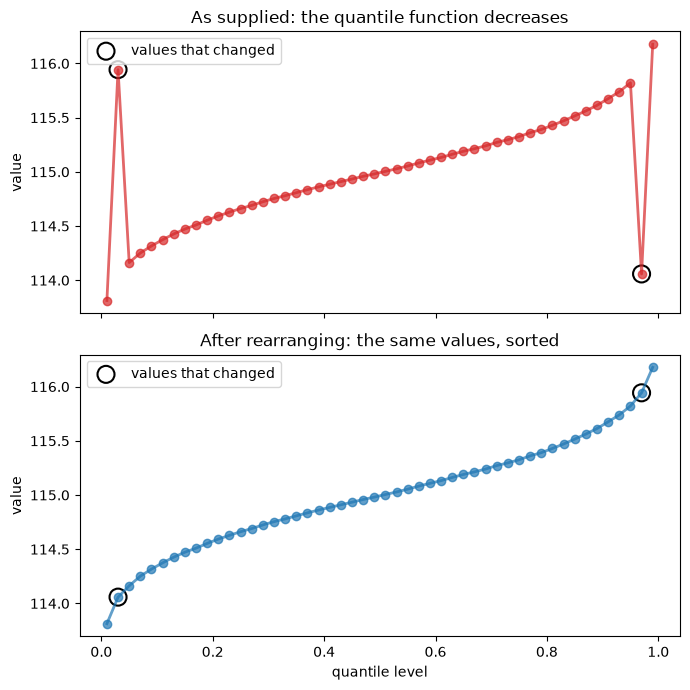

In [ ]:
# Visualise the rearrangement of crossing quantiles
before = crossed.sort_values("quantile")
after = repaired.density_forecasts.sort_values("quantile")
moved = before["value"].to_numpy() != after["value"].to_numpy()

fig, axes = plt.subplots(2, 1, figsize=(7, 7), sharex=True, sharey=True)
for ax, frame, colour, title in [
    (axes[0], before, "tab:red", "As supplied: the quantile function decreases"),
    (axes[1], after, "tab:blue", "After rearranging: the same values, sorted"),
]:
    ax.plot(frame["quantile"], frame["value"], "o-", color=colour, alpha=0.7)
    ax.scatter(
        frame["quantile"][moved], frame["value"][moved], s=150, facecolors="none", edgecolors="black", linewidths=1.5,
        label="values that changed",
    )
    ax.set_ylabel("value")
    ax.set_title(title)
    ax.legend()
axes[1].set_xlabel("quantile level")
fig.tight_layout()
plt.show()

### Filtering

`filter` restricts the density forecasts, the outturns and any point forecasts together, and is atomic: if any table fails to filter, none changes. Fitting and evaluation use the currently filtered densities. `clear_filter()` restores everything.

In [19]:
density_data.filter(variables=["gdpkp"])
print("filtered:", density_data.density_forecasts["variable"].unique().tolist(),
      "| outturn variables:", density_data.outturns["variable"].unique().tolist())
density_data.clear_filter()
print("cleared: ", density_data.density_forecasts["variable"].unique().tolist(),
      "| outturn variables:", density_data.outturns["variable"].unique().tolist())

filtered: ['gdpkp'] | outturn variables: ['gdpkp']
cleared:  ['gdpkp'] | outturn variables: ['cpisa', 'gdpkp']


### Plotting a vintage

`plot_density_vintage` shows one forecast vintage as a fan: the outer pair of requested quantiles is shaded, the median is solid and other levels are faint dashed lines. Outturns from the latest vintage are drawn solid before the forecast vintage and dashed after it. A requested level that is not stored is replaced by the nearest stored level, with a warning.

\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:725: UserWarning: Requested quantile level 0.5 is not stored; using closest available level 0.49.
  return plot_density_vintage(


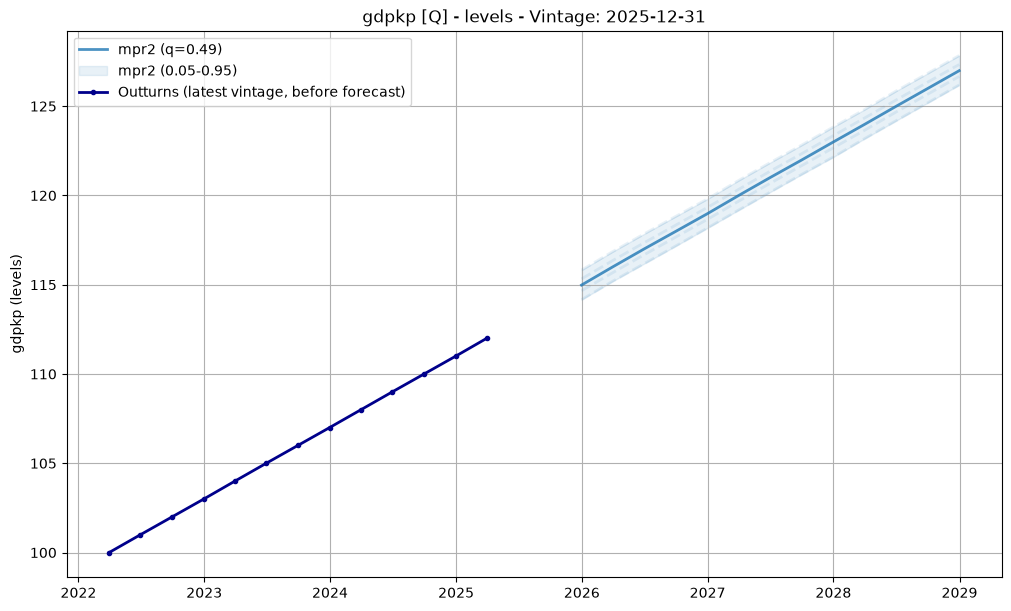

In [21]:
gdp_vintage = density_data.density_forecasts.query("variable == 'gdpkp'")["vintage_date"].max()
density_data.plot_density_vintage(variable="gdpkp", vintage_date=gdp_vintage, quantiles=[0.05, 0.25, 0.5, 0.75, 0.95])

### Sampling and conversion to point forecasts

`sample_from_density` draws from each density by linear interpolation of its quantile function. Draws are independent across densities, and the tails are clamped at the outermost stored quantiles, so sampled tails are too thin on sparse grids. For evaluation, fit a continuous density instead (Part 2).

The chart after the draws compares one density's stored quantiles with its draws. The CDFs agree closely, and the density implied by the stored quantiles (the probability gap between neighbouring quantiles divided by the value gap) matches the histogram. The spikes at either end are the clamping: the probability below the lowest stored quantile, and above the highest, is stacked on those two values.

`to_point_forecast` copies one quantile (default the median) into the point-forecast tables, after which the point-forecast toolkit (accuracy, bias, efficiency tests) applies.

In [24]:
# Sample from the density data via inverse transform sampling
samples = density_data.sample_from_density(n_samples=2000, random_state=42)
print(samples.shape)
samples.head()

Sampling from density: 100%|██████████| 13/13 [00:00<00:00, 1190.37it/s]

(26000, 11)


,date,variable,vintage_date,source,frequency,forecast_horizon,metric,target_minus_vintage,unique_id,sample_id,value
0,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0,levels,0,mpr2,0,115.367064
1,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0,levels,0,mpr2,1,114.920251
2,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0,levels,0,mpr2,2,115.535788
3,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0,levels,0,mpr2,3,115.251574
4,2025-12-31,gdpkp,2025-12-31,mpr2,Q,0,levels,0,mpr2,4,114.328462


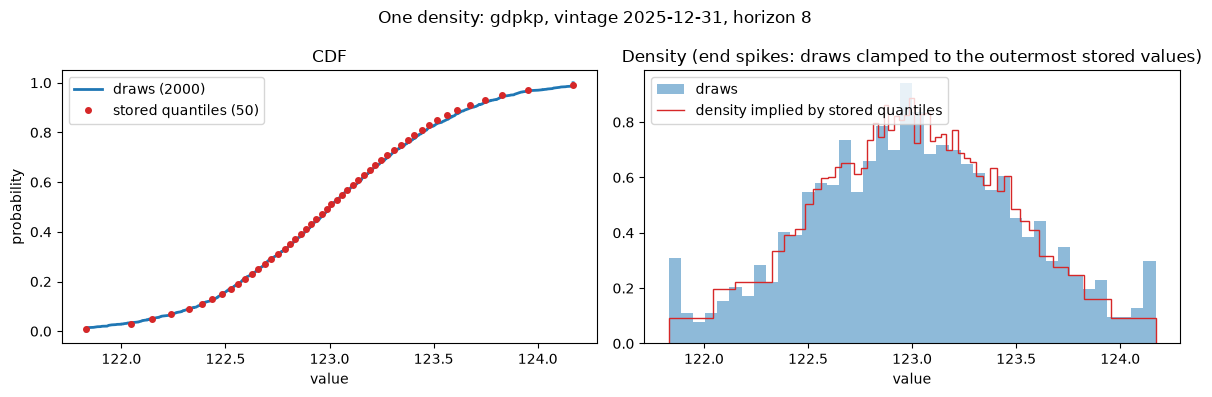

share of draws at the lowest stored value:  1.2% (expected 1.0%)
share of draws at the highest stored value: 1.4% (expected 1.0%)


In [ ]:
# Visualise stored quantiles versus draws from inverse transform sampling, for one forecast horizon from a single forecast origin
horizon = 8
latest = density_data.density_forecasts["vintage_date"].max()
pick = lambda df: df[(df["vintage_date"] == latest) & (df["forecast_horizon"] == horizon)]

stored = pick(density_data.density_forecasts).sort_values("quantile")
p, x = stored["quantile"].to_numpy(), stored["value"].to_numpy()
draws = np.sort(pick(samples)["value"].to_numpy())

fig, (ax_cdf, ax_pdf) = plt.subplots(1, 2, figsize=(12, 4))

ax_cdf.plot(draws, np.arange(1, len(draws) + 1) / len(draws), color="tab:blue", label=f"draws ({len(draws)})")
ax_cdf.plot(x, p, "o", color="tab:red", ms=4, label=f"stored quantiles ({len(p)})")
ax_cdf.set(title="CDF", xlabel="value", ylabel="probability")
ax_cdf.legend(loc="upper left")

ax_pdf.hist(draws, bins=40, density=True, color="tab:blue", alpha=0.5, label="draws")
ax_pdf.stairs(np.diff(p) / np.diff(x), x, color="tab:red", label="density implied by stored quantiles")
ax_pdf.set(title="Density (end spikes: draws clamped to the outermost stored values)", xlabel="value")
ax_pdf.legend(loc="upper left")

fig.suptitle(f"One density: gdpkp, vintage {latest:%Y-%m-%d}, horizon {horizon}")
fig.tight_layout()
plt.show()
print(f"share of draws at the lowest stored value:  {np.mean(draws == x[0]):.1%} (expected {p[0]:.1%})")
print(f"share of draws at the highest stored value: {np.mean(draws == x[-1]):.1%} (expected {1 - p[-1]:.1%})")

In [27]:
# Convert density forecasts to point forecasts using the median
density_data.to_point_forecast(method="median")
print("point forecast rows:", len(density_data.forecasts), "| sources:", density_data.forecasts["source"].unique().tolist())
density_data.forecasts.head()

C:\Users\333415\AppData\Local\Temp\ipykernel_40880\1469765902.py:2: UserWarning: to_point_forecast('median'): quantile level 0.5 is not stored at every date for 1 of 1 forecast(s); used the nearest stored level instead (ties go to the lower level), e.g. source=mpr2, variable=gdpkp, metric=levels, frequency=Q, vintage_date=2025-12-31: level 0.49 (distance 0.01). Pass on_missing='raise' to make this an error.
  density_data.to_point_forecast(method="median")


point forecast rows: 34 | sources: ['mpr2']


,date,variable,vintage_date,frequency,value,metric,target_minus_vintage,unique_id,forecast_horizon,source
0,2025-12-31,gdpkp,2025-12-31,Q,114.980480,levels,0,mpr2,0,mpr2
1,2026-03-31,gdpkp,2025-12-31,Q,115.992746,levels,1,mpr2,1,mpr2
2,2026-06-30,gdpkp,2025-12-31,Q,116.995902,levels,2,mpr2,2,mpr2
3,2026-09-30,gdpkp,2025-12-31,Q,117.983020,levels,3,mpr2,3,mpr2
4,2026-12-31,gdpkp,2025-12-31,Q,118.974714,levels,4,mpr2,4,mpr2


## Part 2: Fitting and evaluating densities on a known answer

The data are synthetic, so the answer is known. Outturns are a persistent signal plus N(0, 1) noise, and two sources forecast the signal at horizons 0 to 4 quarters:

- `calibrated`: N(signal, 1), the true predictive density;
- `overconfident`: N(signal, 0.5), too narrow.

Each density is stored as 19 quantiles (0.05, 0.10, ..., 0.95), the format a model or a forecaster would typically supply.

In [28]:
rng = np.random.default_rng(0)
dates = pd.date_range("2000-03-31", periods=100, freq="QE")
signal = 100 + np.cumsum(rng.normal(0, 0.3, len(dates)))
outturn = signal + rng.standard_normal(len(dates))
levels = np.round(np.arange(1, 20) * 0.05, 2)

outturns = pd.DataFrame(
    {
        "date": dates,
        "vintage_date": dates[-1] + pd.offsets.QuarterEnd(1),  # one outturn vintage, published after the last date
        "variable": "gdp",
        "frequency": "Q",
        "metric": "levels",
        "value": outturn,
    }
)

rows = []
for source, scale in {"calibrated": 1.0, "overconfident": 0.5}.items():
    for h in range(5):
        for d, centre in zip(dates, signal):
            for level, value in zip(levels, stats.norm.ppf(levels, centre, scale)):
                rows.append(
                    {
                        "date": d,
                        "vintage_date": d - pd.offsets.QuarterEnd(h) if h else d,
                        "variable": "gdp",
                        "frequency": "Q",
                        "metric": "levels",
                        "source": source,
                        "forecast_horizon": h,
                        "quantile": level,
                        "value": value,
                    }
                )

data = fe.DensityForecastData(outturns_data=outturns, forecasts_data=pd.DataFrame(rows), data_check=False)
data.density_forecasts.head()

,date,vintage_date,variable,frequency,metric,source,forecast_horizon,quantile,value,target_minus_vintage,unique_id
0,2000-03-31,2000-03-31,gdp,Q,levels,calibrated,0,0.05,98.392865,0,calibrated
1,2000-03-31,2000-03-31,gdp,Q,levels,calibrated,0,0.10,98.756168,0,calibrated
2,2000-03-31,2000-03-31,gdp,Q,levels,calibrated,0,0.15,99.001286,0,calibrated
3,2000-03-31,2000-03-31,gdp,Q,levels,calibrated,0,0.20,99.196098,0,calibrated
4,2000-03-31,2000-03-31,gdp,Q,levels,calibrated,0,0.25,99.363229,0,calibrated


In [30]:
# Print summary of density data 
data.summary()


DATA SUMMARY

[OUTTURNS]
  Number of variables: 1
  Variables: gdp

  Variable | Freq | Date                     | Vintage                 
  ---------------------------------------------------------------------
  gdp      | Q    | 2000-03-31 to 2024-12-31 | 2025-03-31 to 2025-03-31
  ---------------------------------------------------------------------

[FORECASTS] No point forecasts loaded (density forecasts are loaded: see [DENSITY FORECASTS])

[DENSITY FORECASTS]
  Number of variables: 1
  Variables: gdp

  Number of sources: 2
  Sources: calibrated, overconfident

  calibrated
  Variable | Metric | Freq | Date                     | Vintage                  | Horizon 
  -----------------------------------------------------------------------------------------
  gdp      | levels | Q    | 2000-03-31 to 2024-12-31 | 1999-03-31 to 2024-12-31 | 0 to 4  
  -----------------------------------------------------------------------------------------
  Quantile grid:
    gdp, levels: 0.05-0.9

### A look at one forecast origin

`plot_density_vintage` also compares sources. Both sources forecast the same signal, so the medians coincide, but the overconfident fan is half as wide. Over many origins, about 90% of outturns should fall inside the calibrated 5-95% band, and fewer inside the overconfident one. One vintage is only an illustration; the tests below do the formal check.

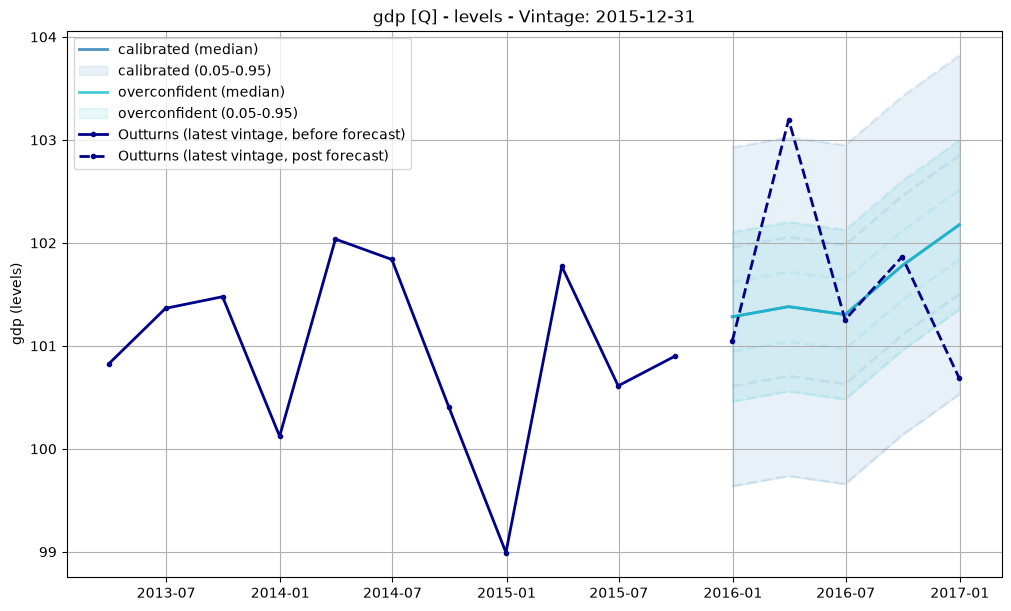

In [31]:
data.plot_density_vintage(
    variable="gdp",
    vintage_date="2015-12-31",
    forecast_source=["calibrated", "overconfident"],
    quantiles=[0.05, 0.25, 0.5, 0.75, 0.95],
    outturn_start_date="2013-01-01",
)

### Fit densities to the quantiles

`fit_parametric_density` fits one density per stored set of quantiles. Here the quantiles are normal, so `"normal"` fits them exactly. For skewed forecasts, use `"skew_t"` or `"two_piece_normal"`; `"mpz"` passes exactly through the quantiles. Known parameters, such as fan-chart two-piece normals, can be supplied with `fe.FittedDensityForecasts.from_params`.

In [32]:
fitted = data.fit_parametric_density("normal")
fitted.params.head()

,date,vintage_date,variable,frequency,metric,source,forecast_horizon,target_minus_vintage,unique_id,loc,scale
0,2000-03-31,1999-03-31,gdp,Q,levels,calibrated,4,4,calibrated,100.037719,1.0
1,2000-03-31,1999-03-31,gdp,Q,levels,overconfident,4,4,overconfident,100.037719,0.5
2,2000-03-31,1999-06-30,gdp,Q,levels,calibrated,3,3,calibrated,100.037719,1.0
3,2000-03-31,1999-06-30,gdp,Q,levels,overconfident,3,3,overconfident,100.037719,0.5
4,2000-03-31,1999-09-30,gdp,Q,levels,calibrated,2,2,calibrated,100.037719,1.0


`plot_fit` below compares one density's stored quantiles with the fitted density, for one source, forecast origin and horizon. The left panel is the CDF, the middle panel the density (the fitted curve against the density implied by joining the stored quantiles), and the right panel the fitted minus stored value at each quantile level, which is what the fit diagnostics summarise. Here the stored quantiles are exactly normal, so the fit is exact and the residuals are zero.

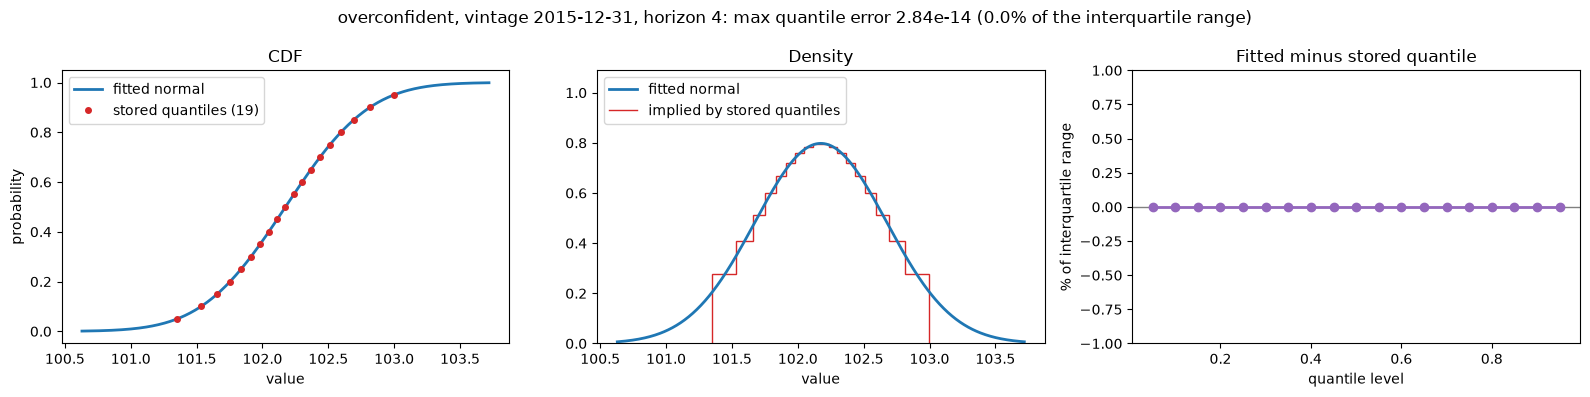

In [34]:
def plot_fit(fitted, source, vintage_date, horizon):
    """Stored quantiles versus the fitted density for one source, forecast origin and horizon."""
    vintage_date = pd.Timestamp(vintage_date)
    match = lambda df: (df["source"] == source) & (df["vintage_date"] == vintage_date) & (df["forecast_horizon"] == horizon)

    rows = np.flatnonzero(match(fitted.keys))
    if rows.size != 1:
        raise ValueError(f"Expected one density, found {rows.size}.")
    row = rows[0]

    table = fitted.data.density_forecasts
    stored = table[match(table)].sort_values("quantile")
    p, x = stored["quantile"].to_numpy(), stored["value"].to_numpy()

    one = fitted.take([row])
    lo, hi = one.ppf([0.001, 0.999])[0]
    grid = np.linspace(min(lo, x[0]), max(hi, x[-1]), 400)
    diag = fitted.diagnostics.iloc[row]
    iqr = np.subtract(*one.ppf([0.75, 0.25])[0])

    fig, (ax_cdf, ax_pdf, ax_err) = plt.subplots(1, 3, figsize=(16, 4))

    ax_cdf.plot(grid, one.cdf(grid)[0], color="tab:blue", label=f"fitted {fitted.method}")
    ax_cdf.plot(x, p, "o", color="tab:red", ms=4, label=f"stored quantiles ({len(p)})")
    ax_cdf.set(title="CDF", xlabel="value", ylabel="probability")
    ax_cdf.legend(loc="upper left")

    ax_pdf.plot(grid, one.pdf(grid)[0], color="tab:blue", label=f"fitted {fitted.method}")
    ax_pdf.stairs(np.diff(p) / np.diff(x), x, color="tab:red", label="implied by stored quantiles")
    ax_pdf.set(title="Density", xlabel="value", ylim=(0, ax_pdf.get_ylim()[1] * 1.3))
    ax_pdf.legend(loc="upper left")

    error = 100 * (one.ppf(p)[0] - x) / iqr
    ax_err.axhline(0, color="grey", lw=1)
    ax_err.plot(p, error, "o-", color="tab:purple")
    ax_err.set(
        title="Fitted minus stored quantile", xlabel="quantile level", ylabel="% of interquartile range",
        ylim=(min(-1, error.min() * 1.1), max(1, error.max() * 1.1)),
    )

    fig.suptitle(
        f"{source}, vintage {vintage_date:%Y-%m-%d}, horizon {horizon}: "
        f"max quantile error {diag['max_abs_error']:.3g} ({diag['relative_error']:.1%} of the interquartile range)"
    )
    fig.tight_layout()
    plt.show()


plot_fit(fitted, source="overconfident", vintage_date="2015-12-31", horizon=4)

### Calibration

PITs of the outturns should be uniform for a calibrated density. The overconfident source has too many PITs in the tails.

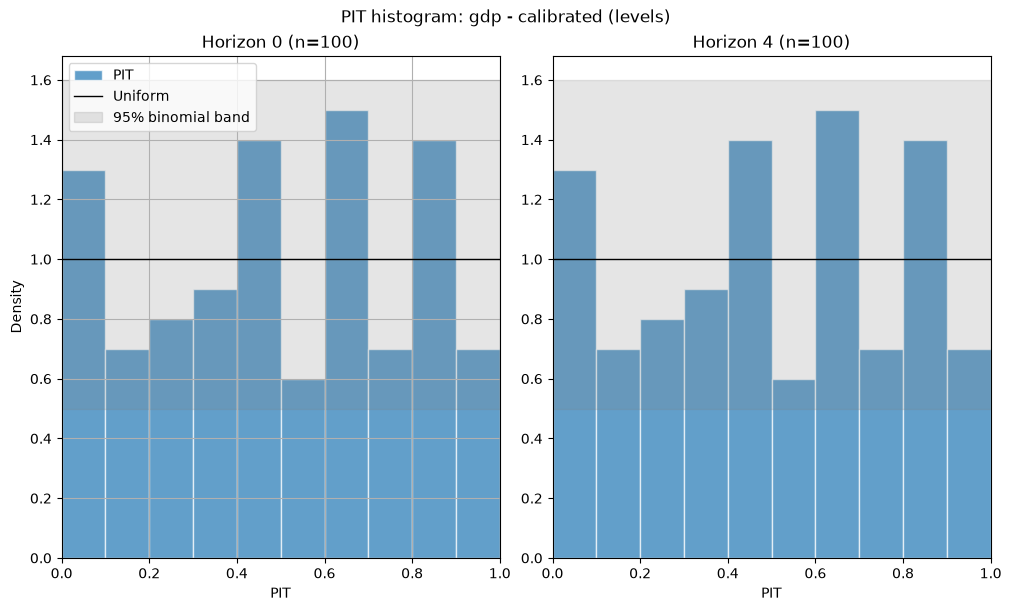

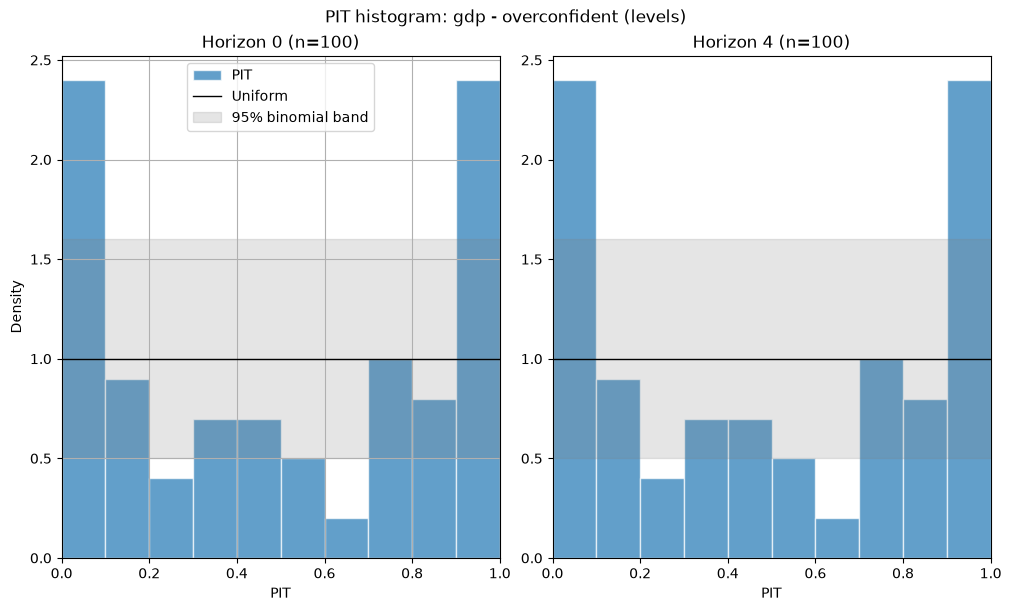

In [53]:
pit = fe.compute_pit(fitted, k="latest")
pit.plot(source="calibrated", horizons=[0, 4])
pit.plot(source="overconfident", horizons=[0, 4])

In [ ]:

cols = ["unique_id", "horizon", "stat", "p_value", "n_observations"]
knuppel = fe.knuppel_test(fitted, k="latest").to_df()[cols]
mitchell_weale = fe.mitchell_weale_test(fitted, k="latest").to_df()[cols]
knuppel.merge(mitchell_weale, on=["unique_id", "horizon", "n_observations"], suffixes=("_knuppel", "_mw"))

,unique_id,horizon,stat_knuppel,p_value_knuppel,n_observations,stat_mw,p_value_mw
0,calibrated,0,3.251834,0.516600,100,1.800907,0.875950
1,calibrated,1,3.251834,0.516600,100,1.800907,0.875950
2,calibrated,2,3.251834,0.516600,100,1.800907,0.875950
3,calibrated,3,3.251834,0.516600,100,1.800907,0.875950
4,calibrated,4,3.251834,0.516600,100,1.800907,0.875950
5,overconfident,0,13.122733,0.010691,100,14.896104,0.010816
6,overconfident,1,13.122733,0.010691,100,14.896104,0.010816
7,overconfident,2,13.122733,0.010691,100,14.896104,0.010816
8,overconfident,3,13.122733,0.010691,100,14.896104,0.010816
9,overconfident,4,13.122733,0.010691,100,14.896104,0.010816


Rossi-Sekhposyan bootstrap critical values allow for the serial correlation of multi-step PITs. Their bands can be added to the PIT ECDF plot.

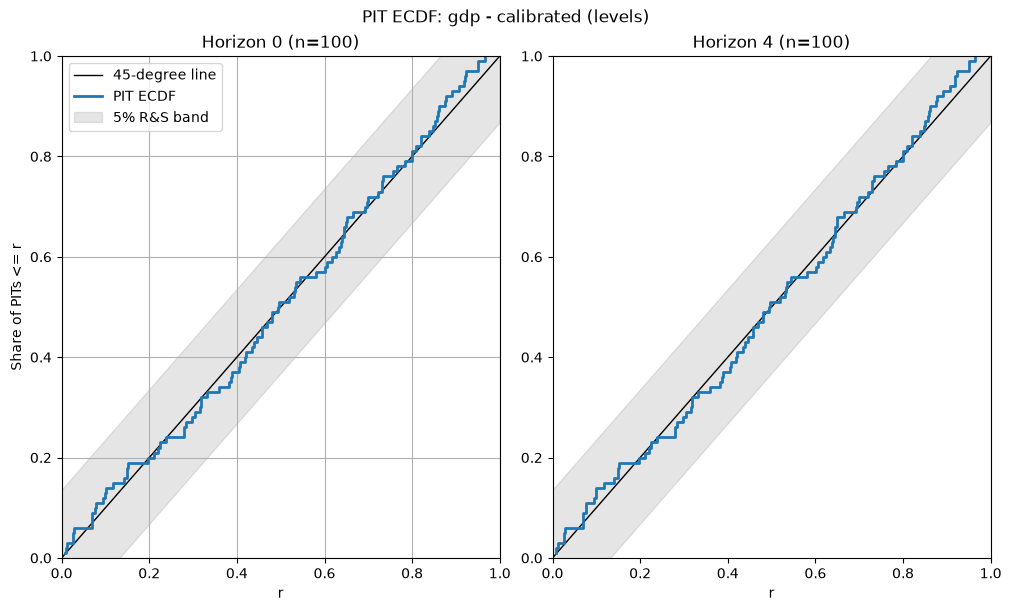

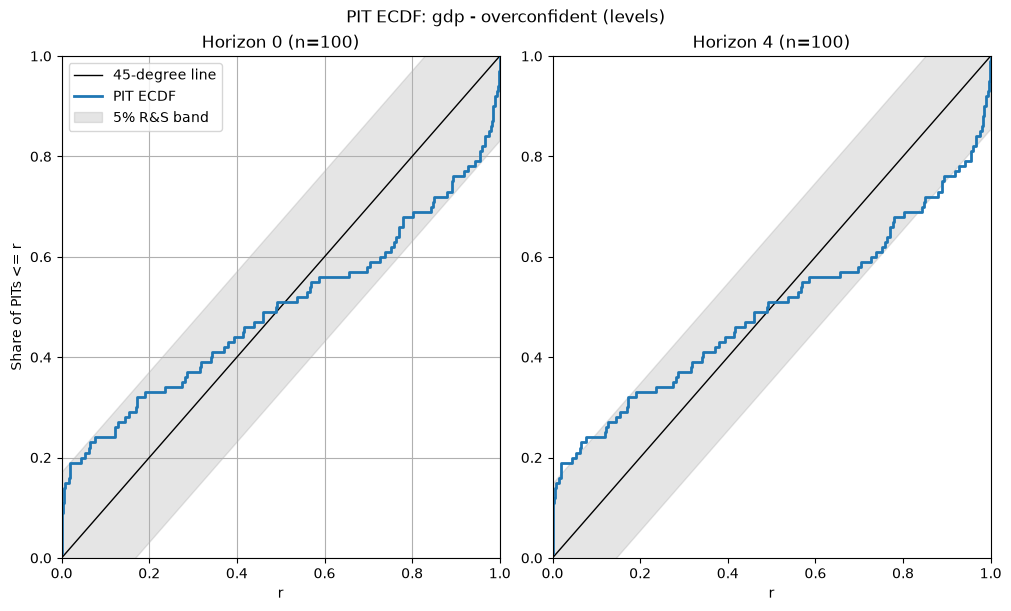

In [39]:
rs = fe.rossi_sekhposyan_test(fitted, k="latest", seed=0)
pit.plot(kind="ecdf", source="calibrated", horizons=[0, 4], rs_result=rs)
pit.plot(kind="ecdf", source="overconfident", horizons=[0, 4], rs_result=rs)

The Galvao-Mantoan-Mitchell test checks every horizon jointly, using forecast origins that have all horizons.

In [7]:
fe.galvao_mantoan_mitchell_test(fitted, k="latest", seed=0).to_df()

,variable,unique_id,metric,frequency,horizons,ks_stat,ks_cv,ks_reject,cvm_stat,cvm_cv,cvm_reject,block_length,n_observations,start_date,end_date,source
0,gdp,calibrated,levels,Q,"(0, 1, 2, 3, 4)",0.582643,1.381404,False,0.050932,0.577384,False,4,96,2000-03-31,2023-12-31,calibrated
1,gdp,overconfident,levels,Q,"(0, 1, 2, 3, 4)",1.743024,1.403840,True,1.122411,0.716498,True,4,96,2000-03-31,2023-12-31,overconfident


### Accuracy and sharpness

Sharpness explanation here...

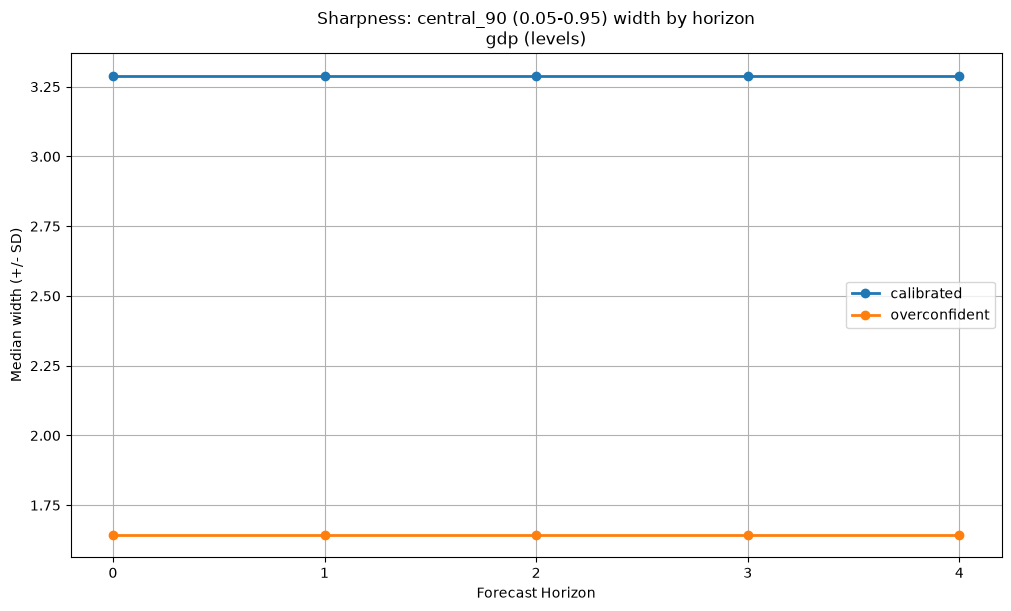

In [11]:
fe.sharpness_analysis(fitted, k="latest").plot(interval="central_90")

The CRPS rewards calibration and sharpness together, and lower is better. `weight="left"` focuses on downside risk. The overconfident source is sharper but scores worse.

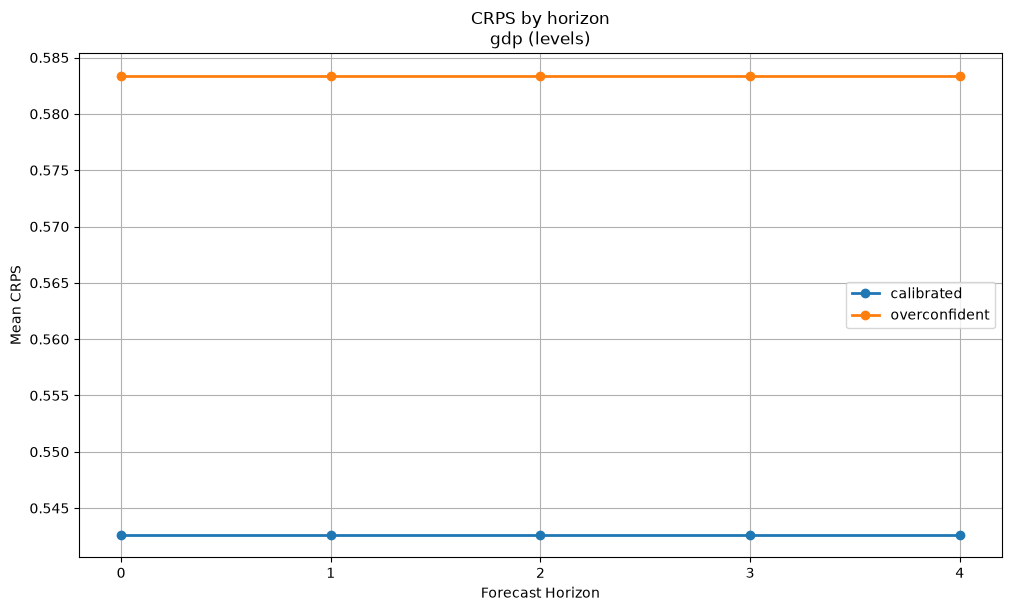

In [40]:
crps = fe.crps_analysis(fitted, k="latest")
crps.plot()

In [9]:
fe.crps_analysis(fitted, k="latest", weight="left").to_df()[["unique_id", "horizon", "crps", "n_observations"]]

,unique_id,horizon,crps,n_observations
0,calibrated,0,0.171959,100
1,calibrated,1,0.171959,100
2,calibrated,2,0.171959,100
3,calibrated,3,0.171959,100
4,calibrated,4,0.171959,100
5,overconfident,0,0.191224,100
6,overconfident,1,0.191224,100
7,overconfident,2,0.191224,100
8,overconfident,3,0.191224,100
9,overconfident,4,0.191224,100


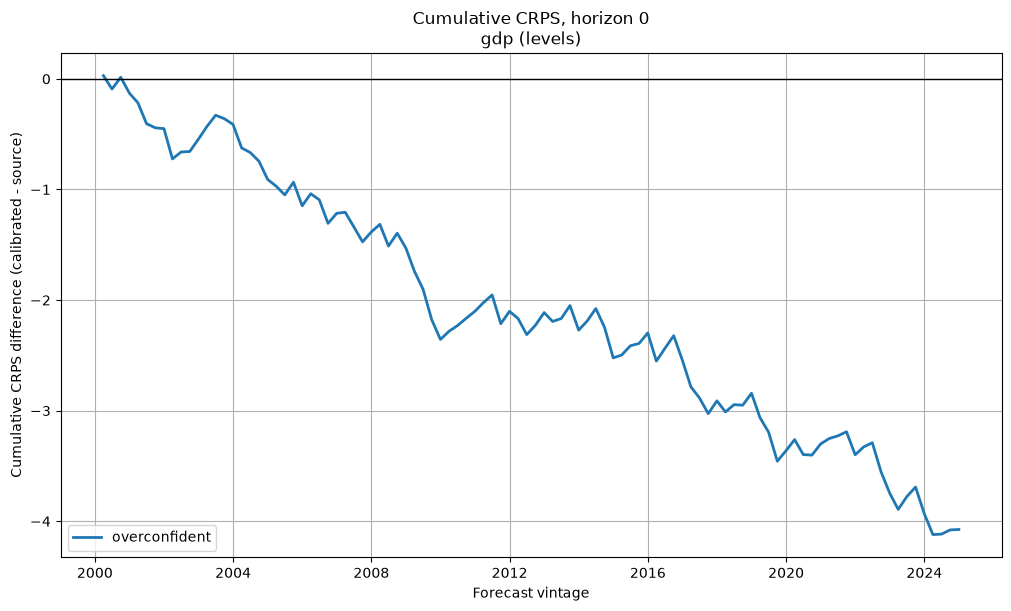

In [10]:
fe.compute_crps(fitted, k="latest").plot(horizon=0, benchmark="calibrated")

## Part 3: End to end with OPERA: BVAR density forecasts of UK CPI inflation

This part produces real-time density forecasts with the OPERA `bvar` model, through `forecast_realtime`, on the vintaged UK data shipped with `forecast_evaluation` (FER data). It then evaluates them with the metrics used for inflation in the MTP: Knüppel and Mitchell-Weale calibration tests, PIT histograms and ECDFs, Rossi-Sekhposyan and Galvão-Mantoan-Mitchell tests, CRPS, right-tail weighted CRPS, and sharpness.

The specification follows the MTP's inflation BVAR as far as the FER data allow:

| | MTP inflation BVAR (MATLAB) | Here |
|---|---|---|
| Target | 12-month CPI inflation, monthly data | four-quarter CPI inflation (`cpisa`, `yoy`), quarterly data |
| Other variables | inflation persistence, inflation expectations, unemployment, oil prices, bond spread | unemployment rate (`unemp`, levels), wage growth (`aweagg`, `yoy`), GDP growth (`gdpkp`, `yoy`) |
| Prior | Minnesota, random-walk prior mean for every variable | natural-conjugate Minnesota (`bvar` defaults), random-walk prior mean (`stationary=False`) |
| Lags | 1 month | 4 quarters |
| Forecast origins | quarterly, 2010Q1 to 2022Q3, final-vintage data | quarterly vintages 2010Q1 to 2022Q3, each using only the data published by then |
| Horizons | 0 to 12 quarters | 0 to 12 quarters |
| Density | normal, with the predictive mean and standard deviation | 19 quantiles (0.05 to 0.95) of the predictive draws, fitted with a normal |

A smaller BVAR (CPI inflation and unemployment only) is a second source, so the evaluation compares two models. Expect a few minutes: two models, 51 vintages each.

In [41]:
import time

import forecast_realtime as rt

BVAR_MTP = {"cpisa": "yoy", "unemp": "levels", "aweagg": "yoy", "gdpkp": "yoy"}  # variable -> model input metric
BVAR_SMALL = {"cpisa": "yoy", "unemp": "levels"}
GRID = np.round(np.arange(1, 20) * 0.05, 2).tolist()  # the MTP's 19 quantile levels
STEPS = 13  # horizons 0..12 quarters
FIRST_VINTAGE, LAST_VINTAGE = "2010-03-31", "2022-09-30"
N_LAGS, N_SAMPLES, N_DRAWS = 4, 2000, 5000
K = "latest"  # score against the latest outturn vintage, like the MTP's final data

### Run the BVARs over the vintages

`RealTimeModel.forecast(..., quantiles=GRID)` loops over the vintages, fits each BVAR on the data published by that vintage and returns the predictive quantiles as a long table in `rt_model.quantiles`. It does not return a `DensityForecastData`. `data_transformation` selects the outturn metric each variable enters the model in, and the quantiles come back in that metric. Horizon 0 is the quarter that ends on the vintage date, which has not yet been published.

In [42]:
def load_fer():
    # The embedded file holds levels only; the loader labels them and derives pop and yoy.
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="Outturns input has no 'metric' column")
        return fe.ForecastData(load_fer=True)


def run_bvar(variables, label):
    model = rt.models.ForecastBVAR(
        stationary=False,  # random-walk prior mean, as in the MTP
        n_lags=N_LAGS,
        optimisation_method="none",
        n_samples=N_SAMPLES,
        N_draws=N_DRAWS,
        progressbar=False,
        label=label,
    )
    rt_model = rt.RealTimeModel(data=load_fer(), models=model)
    start = time.perf_counter()
    rt_model.forecast(
        y_variables=list(variables),
        data_transformation=variables,
        step_frequency="Q",
        steps=STEPS,
        first_vintage=FIRST_VINTAGE,
        last_vintage=LAST_VINTAGE,
        quantiles=GRID,
    )
    quantiles = rt_model.quantiles
    print(f"{label}: {quantiles['vintage_date'].nunique()} vintages in {time.perf_counter() - start:.0f}s")
    return quantiles


raw = pd.concat([run_bvar(BVAR_MTP, "bvar_mtp"), run_bvar(BVAR_SMALL, "bvar_small")], ignore_index=True)
raw.head()

Running bvar_mtp: 100%|██████████| 51/51 [02:54<00:00,  3.42s/it]


bvar_mtp: 51 vintages in 175s


Running bvar_small: 100%|██████████| 51/51 [00:58<00:00,  1.15s/it]

bvar_small: 51 vintages in 59s


,date,variable,quantile,value,forecast_horizon,vintage_date,metric,source,frequency
0,2010-03-31,aweagg,0.05,0.006885,0,2010-03-31,yoy,bvar_mtp,Q
1,2010-03-31,aweagg,0.10,0.010048,0,2010-03-31,yoy,bvar_mtp,Q
2,2010-03-31,aweagg,0.15,0.012226,0,2010-03-31,yoy,bvar_mtp,Q
3,2010-03-31,aweagg,0.20,0.014075,0,2010-03-31,yoy,bvar_mtp,Q
4,2010-03-31,aweagg,0.25,0.015487,0,2010-03-31,yoy,bvar_mtp,Q


### Reshape to the density schema

Keep the CPI inflation densities, select the schema columns, and check the assumptions the evaluation relies on: a complete quantile grid, no crossing, and horizons 0 to 12 for every vintage.

In [43]:
SCHEMA = ["date", "vintage_date", "variable", "source", "frequency", "forecast_horizon", "quantile", "value", "metric"]

density = raw.loc[(raw["variable"] == "cpisa") & (raw["metric"] == "yoy"), SCHEMA].copy()
density["date"] = pd.to_datetime(density["date"]).dt.normalize()
density["vintage_date"] = pd.to_datetime(density["vintage_date"]).dt.normalize()
density = density.astype({"quantile": float, "value": float, "forecast_horizon": int})

wide = density.pivot_table(index=["source", "vintage_date", "date"], columns="quantile", values="value")
assert not density.isna().any().any()
assert np.allclose(wide.columns, GRID) and wide.notna().all().all(), "incomplete quantile grid"
assert (np.diff(wide.to_numpy(), axis=1) >= 0).all(), "quantile crossing"
assert sorted(density["forecast_horizon"].unique()) == list(range(STEPS))
assert (density.groupby(["source", "vintage_date"])["forecast_horizon"].nunique() == STEPS).all()

density.groupby("source").agg(
    vintages=("vintage_date", "nunique"),
    first_vintage=("vintage_date", "min"),
    last_vintage=("vintage_date", "max"),
    densities=("value", lambda s: len(s) // len(GRID)),
)

,vintages,first_vintage,last_vintage,densities
source,,,,
bvar_mtp,51,2010-03-31,2022-09-30,663
bvar_small,51,2010-03-31,2022-09-30,663


### Build `DensityForecastData`

Pass only the `levels` outturns: the object derives `pop` and `yoy` itself, and passing `data.outturns` with all three metrics would store the derived rows twice.

source      metric
bvar_mtp    yoy       12597
bvar_small  yoy       12597
dtype: int64


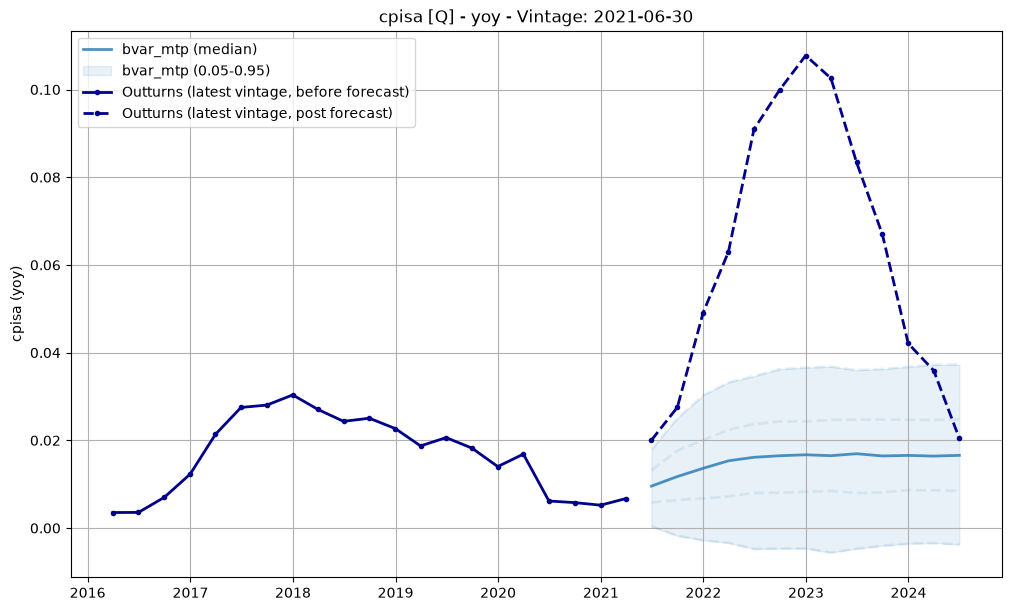

In [44]:
fer_outturns = load_fer().outturns
cpi_levels = fer_outturns[(fer_outturns["variable"] == "cpisa") & (fer_outturns["metric"] == "levels")]
cpi = fe.DensityForecastData(outturns_data=cpi_levels, forecasts_data=density)
print(cpi.density_forecasts.groupby(["source", "metric"]).size())

cpi.plot_density_vintage(
    variable="cpisa", vintage_date="2021-06-30", forecast_source=["bvar_mtp"], metric="yoy",
    quantiles=[0.05, 0.25, 0.5, 0.75, 0.95], outturn_start_date="2016-01-01",
)

### Fit a density to each forecast

The MTP evaluates its BVAR as a normal density with the predictive mean and standard deviation, so the 19 quantiles are fitted with a normal. The diagnostics show how closely the fitted normal reproduces the stored quantiles. `relative_error` is the largest quantile miss as a share of the fitted interquartile range, and a warning is issued above 5%. `"skew_t"` would capture skewed predictive draws, at a longer run time.

In [46]:
fitted_cpi = cpi.fit_parametric_density("normal")
print(fitted_cpi.diagnostics[["max_abs_error", "relative_error"]].describe().round(4))
fitted_cpi.params.head()

       max_abs_error  relative_error
count      1326.0000       1326.0000
mean          0.0015          0.0485
std           0.0126          0.0641
min           0.0001          0.0119
25%           0.0003          0.0274
50%           0.0005          0.0368
75%           0.0007          0.0515
max           0.3097          1.1491


\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:610: UserWarning: Fitted normal quantiles differ from the stored quantiles by more than 0.05 x the fitted interquartile range for 356 of 1326 densities (largest 1.15); see FittedDensityForecasts.diagnostics.
  return fit_quantile_densities(


,date,vintage_date,variable,source,frequency,forecast_horizon,metric,target_minus_vintage,unique_id,loc,scale
0,2010-03-31,2010-03-31,cpisa,bvar_mtp,Q,0,yoy,0,bvar_mtp,0.020471,0.005531
1,2010-03-31,2010-03-31,cpisa,bvar_small,Q,0,yoy,0,bvar_small,0.020446,0.004647
2,2010-06-30,2010-03-31,cpisa,bvar_mtp,Q,1,yoy,1,bvar_mtp,0.020319,0.008408
3,2010-06-30,2010-03-31,cpisa,bvar_small,Q,1,yoy,1,bvar_small,0.020101,0.006350
4,2010-06-30,2010-06-30,cpisa,bvar_mtp,Q,0,yoy,0,bvar_mtp,0.034836,0.005489


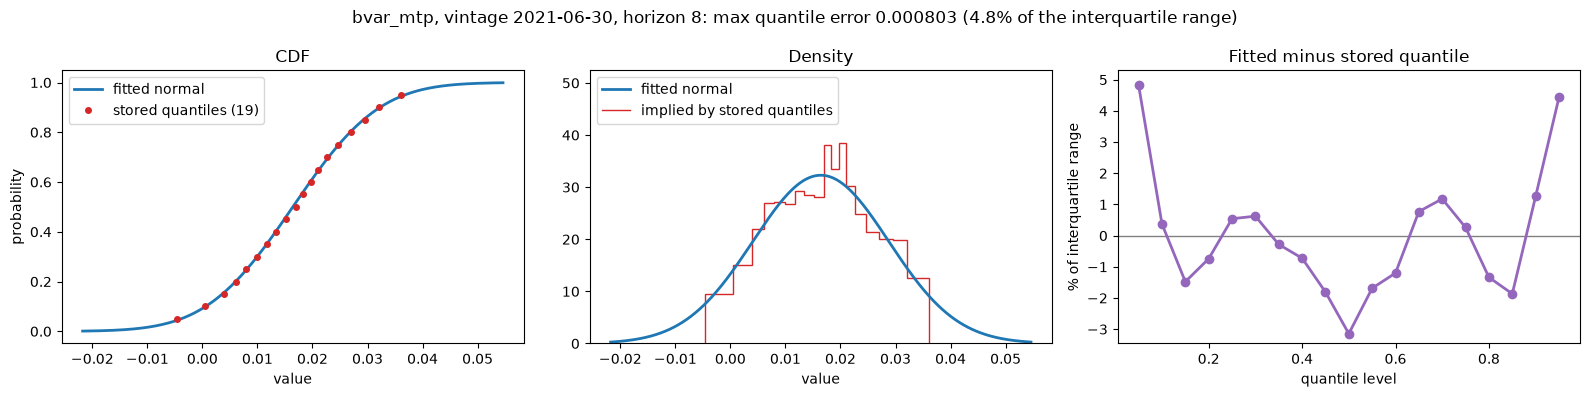

In [47]:
plot_fit(fitted_cpi, source="bvar_mtp", vintage_date="2021-06-30", horizon=8)

### The MTP evaluation table

The MTP's inflation table reports, by horizon, the Knüppel and Mitchell-Weale p-values, the mean CRPS and the mean right-tail weighted CRPS (weight $\tau^2$, emphasising upside inflation risk). With `same_date_range=True` (the default) both models are scored on the same forecast origins.

In [48]:
def by_horizon(result, column):
    return result.to_df().pivot(index="horizon", columns="unique_id", values=column)


crps = fe.crps_analysis(fitted_cpi, k=K)
table = pd.concat(
    {
        "Knueppel p-value": by_horizon(fe.knuppel_test(fitted_cpi, k=K), "p_value"),
        "Mitchell-Weale p-value": by_horizon(fe.mitchell_weale_test(fitted_cpi, k=K), "p_value"),
        "CRPS (mean)": by_horizon(crps, "crps"),
        "wCRPS right tail (mean)": by_horizon(fe.crps_analysis(fitted_cpi, k=K, weight="right"), "crps"),
    },
    axis=1,
)
table.loc[[0, 1, 2, 3, 4, 8, 12]].round(3)

Knueppel p-value            Mitchell-Weale p-value            CRPS (mean)            wCRPS right tail (mean)           
unique_id         bvar_mtp bvar_small               bvar_mtp bvar_small    bvar_mtp bvar_small                bvar_mtp bvar_small
horizon                                                                                                                          
0                    0.350      0.300                  0.410      0.404       0.004      0.003                   0.001      0.001
1                    0.203      0.206                  0.490      0.287       0.007      0.006                   0.002      0.002
2                    0.296      0.263                  0.385      0.299       0.010      0.009                   0.004      0.003
3                    0.341      0.237                  0.394      0.156       0.012      0.012                   0.005      0.005
4                    0.345      0.256                  0.247      0.144       0.014      0.014                   0.005      0.005
8                    0.665      0.736                  0.533      0.500       0.016      0.015                   0.006      0.006
12                   0.497      0.539                  0.284      0.336       0.016      0.015                   0.006      0.006

### PITs and path calibration

PIT histograms with 95% binomial bands, and PIT ECDFs with Rossi-Sekhposyan 5% bands. The bootstrap bands allow for the serial correlation of overlapping multi-step forecasts. The Galvão-Mantoan-Mitchell test then asks whether the whole path of horizons is calibrated.

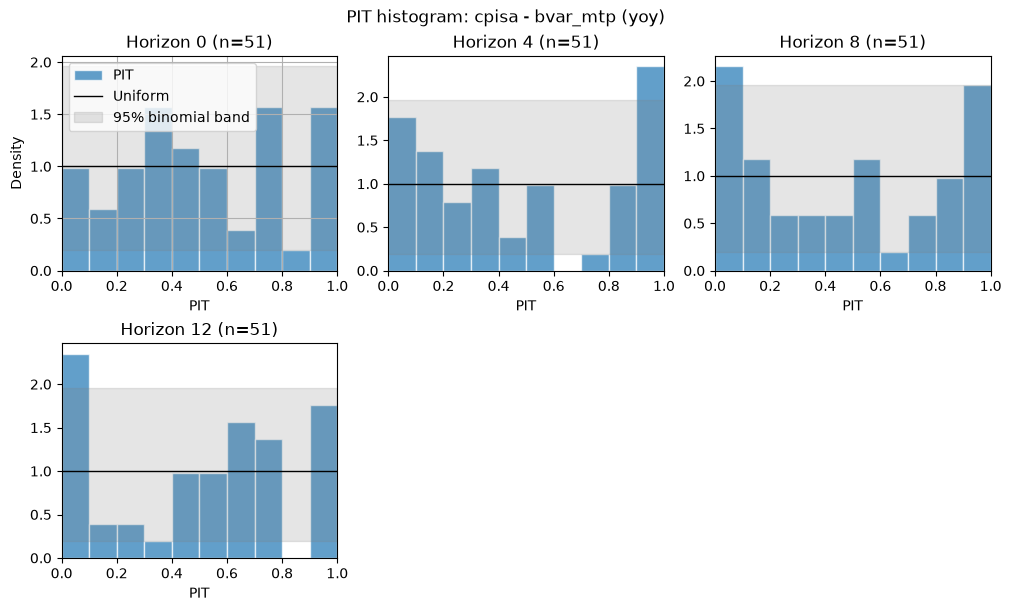

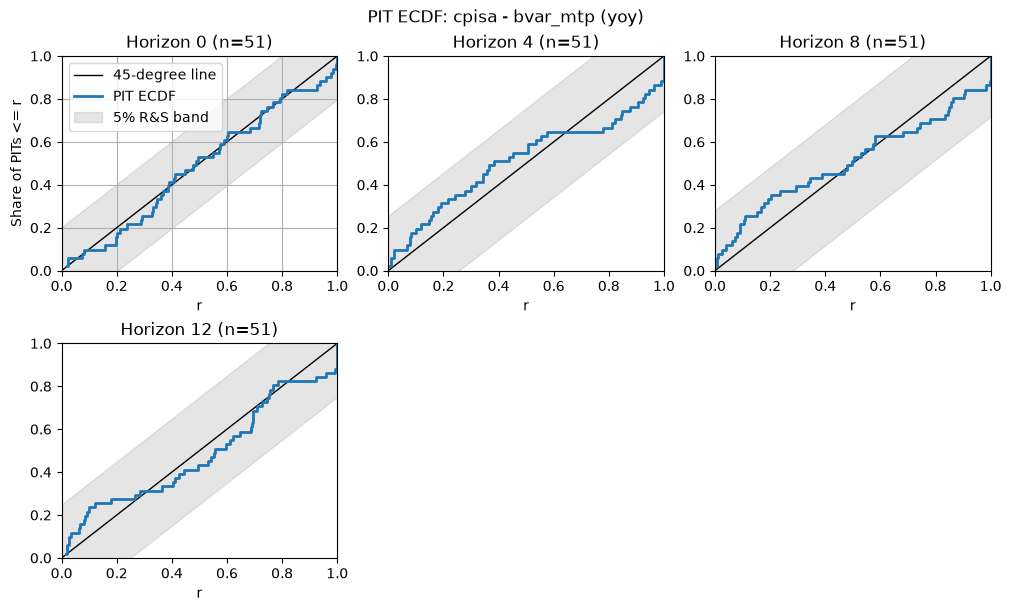

In [49]:
pit_cpi = fe.compute_pit(fitted_cpi, k=K)
rs_cpi = fe.rossi_sekhposyan_test(fitted_cpi, k=K, seed=0)
pit_cpi.plot(source="bvar_mtp", horizons=[0, 4, 8, 12])
pit_cpi.plot(kind="ecdf", source="bvar_mtp", horizons=[0, 4, 8, 12], rs_result=rs_cpi)

In [50]:
fe.galvao_mantoan_mitchell_test(fitted_cpi, k=K, seed=0).to_df()

,variable,unique_id,metric,frequency,horizons,ks_stat,ks_cv,ks_reject,cvm_stat,cvm_cv,cvm_reject,block_length,n_observations,start_date,end_date,source
0,cpisa,bvar_mtp,yoy,Q,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)",1.225350,2.194142,False,0.424984,2.079870,False,3,51,2010-03-31,2022-09-30,bvar_mtp
1,cpisa,bvar_small,yoy,Q,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)",1.571425,2.131847,False,0.451670,2.001826,False,3,51,2010-03-31,2022-09-30,bvar_small


### Accuracy and sharpness

Mean CRPS by horizon; the cumulative CRPS difference against the small BVAR at the one-year horizon, where a rising line means `bvar_mtp` is gaining; and the width of the central 50% interval.

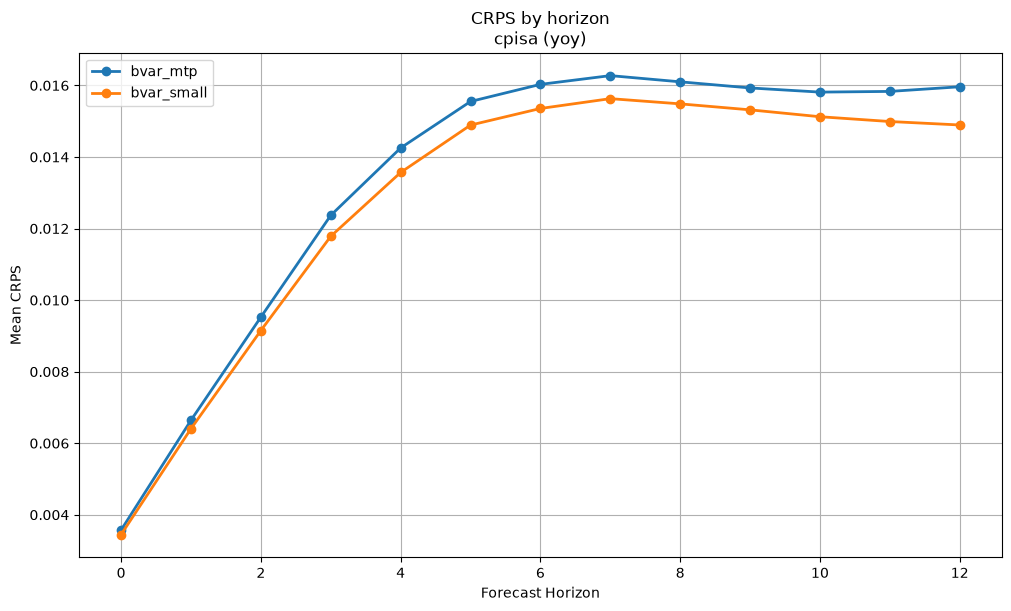

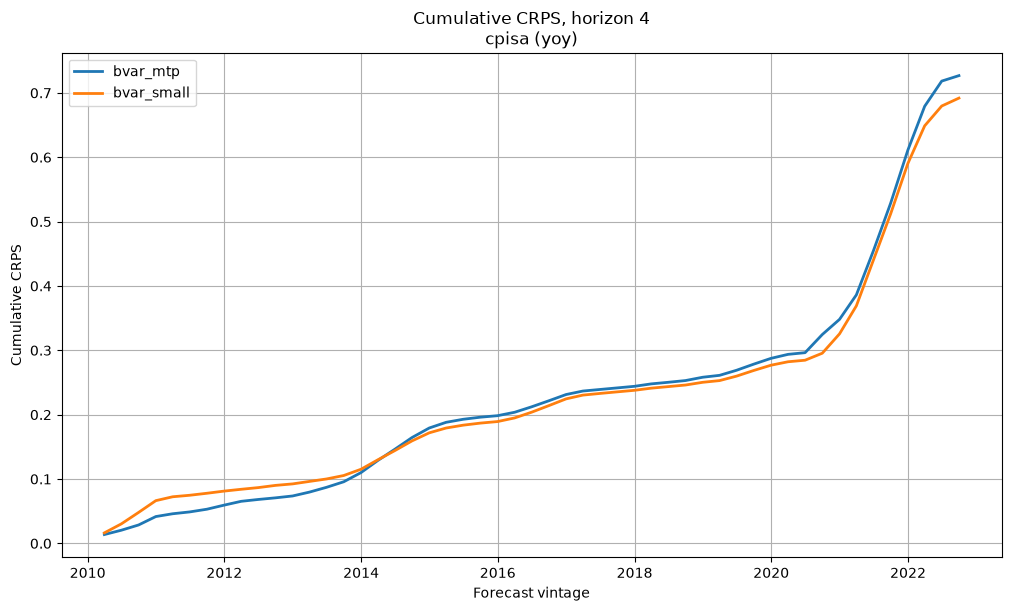

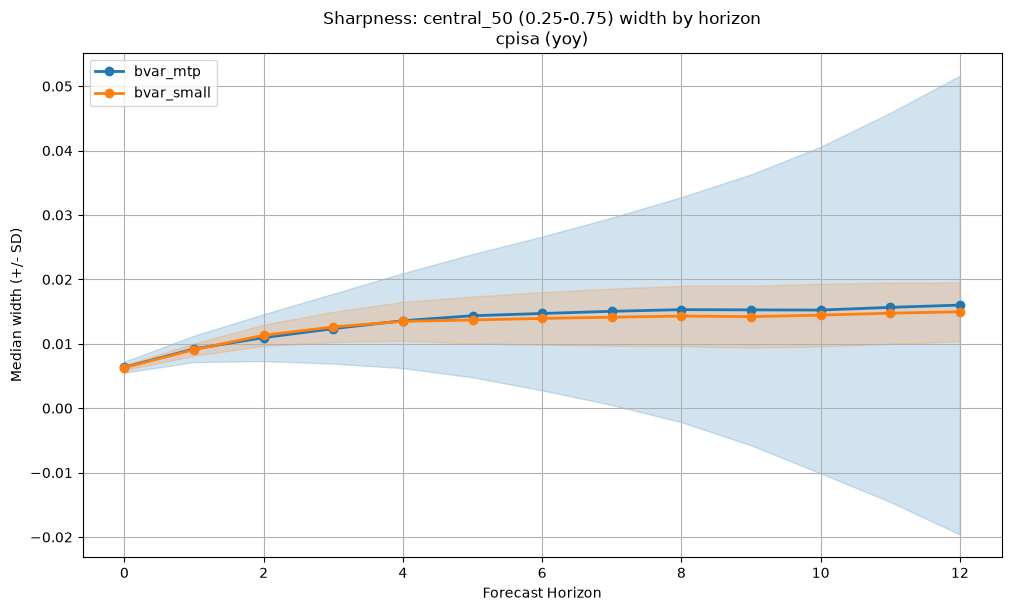

In [52]:
crps.plot()
fe.compute_crps(fitted_cpi, k=K).plot(horizon=4)
fe.sharpness_analysis(fitted_cpi, k=K).plot(interval="central_50")

### Hand-off to point-forecast evaluation

The median of each density can also be scored as a point forecast with the existing toolkit.

In [1]:
cpi.to_point_forecast(method="median")
accuracy = fe.compute_accuracy_statistics(cpi).to_df()
accuracy[accuracy["metric"] == "yoy"].pivot_table(index="horizon", columns="unique_id", values="rmse").round(4)

NameError: name 'cpi' is not defined

### Reading the results

- **Sample size.** There are 51 forecast origins per horizon, and multi-step forecasts overlap, so the tests have limited power. The HAC and bootstrap methods account for the overlap but cannot add information.
- **Real time versus final data.** Each BVAR uses only the data published at its vintage, and is scored against the latest outturns, while the MTP fits on final-vintage data. Real-time results are the more honest measure of forecast performance.
- **COVID.** As in the MTP for inflation, no periods are excluded. The 2021-2023 inflation surge lies at the long horizons of the later origins.
- **Simulation noise.** The quantiles come from 5000 predictive draws per vintage, and the bootstrap tests depend on `seed`.
- **Specification.** The FER data have no inflation expectations, oil prices or financial conditions, so this BVAR is a simplified analogue of the MTP's, not a replication. The prior hyper-parameters are not optimised (`optimisation_method="none"`).

## Part 4: A large real-time BVAR on the COMPASS variables

Part 3's BVAR is limited by the FER data. This part uses the vintaged data on the 20 variables that enter COMPASS, saved from FAME by `notebooks/compass_vintages_data.py`. It runs a 20-variable BVAR in real time over the 45 quarterly vintages from 2015Q1 to 2026Q1, in two variants: unconditional, and conditional on the MPR's assumptions for rates, sterling, fiscal policy and the world. It checks both against the outturns and the MPR forecasts, then evaluates their CPI inflation densities side by side.

| Group | Variables | Enters the model as |
|---|---|---|
| Prices and wages | `cpisa` (UK CPI), `cpif` (foreign CPI), `pxdef`, `pmdef`, `pxfdef` (export, import and world export deflators), `awerps`, `aweagg` (AWE) | four-quarter growth (`yoy`), so CPI inflation is modelled directly |
| Real activity and sterling | `gdpkp`, `ckp`, `ikkp`, `gonskp`, `xkp`, `mkp`, `hrs`, `gdpfkp`, `yf`, `eer` | log levels (`logs`) |
| Rates | `rga` (Bank Rate), `rgaf` (foreign rate), `unemp` | levels |

The prior follows the large-BVAR practice of Giannone, Lenza and Primiceri (2015): Minnesota, sum-of-coefficients and single-unit-root priors, with hyper-parameters chosen by maximising the marginal likelihood (`optimisation_method="ml"`) at each vintage. `stationary=False` sets a random-walk prior mean for every variable. It suits the log levels and the persistent inflation rates, and the sum-of-coefficients and single-unit-root priors are only active with it. COVID dummies (`covid=True`) stop the 2020 swings from dominating the estimates. The model has 5 lags and keeps 1,000 posterior draws per vintage.

A full run takes about 30 minutes for the unconditional BVAR and about 70 for the conditional one. The quantiles are cached to `notebooks/cache/`, and later runs reload them. Delete a file to refit that variant.

In [66]:
from pathlib import Path
import time

import forecast_realtime as rt

COMPASS_DIR = Path("N:/Cross Divisional Work/ma-forecast-real-time/data")
CACHE = Path("cache/compass_bvar_quantiles.parquet")  # relative to the notebook folder
COMPASS_TRANSFORM = {
    **dict.fromkeys(["cpisa", "cpif", "pxdef", "pmdef", "pxfdef", "awerps", "aweagg"], "yoy"),
    **dict.fromkeys(["gdpkp", "ckp", "ikkp", "gonskp", "xkp", "mkp", "hrs", "gdpfkp", "yf", "eer"], "logs"),
    **dict.fromkeys(["rga", "rgaf", "unemp"], "levels"),
}
COMPASS_GRID = np.round(np.arange(1, 20) * 0.05, 2).tolist()
COMPASS_STEPS = 13  # horizons 0..12 quarters

compass_outturns = pd.read_parquet(COMPASS_DIR / "compass_variables_outturns.parquet")
compass_outturns = compass_outturns[
    compass_outturns["variable"].isin(COMPASS_TRANSFORM) & (compass_outturns["date"] >= "1990-01-01")
]
mpr = pd.read_parquet(COMPASS_DIR / "compass_variables_forecasts.parquet")

assert compass_outturns["variable"].nunique() == len(COMPASS_TRANSFORM) == 20
assert (compass_outturns["frequency"] == "Q").all() and (mpr["source"] == "mpr").all()
vintages = sorted(compass_outturns["vintage_date"].unique())
assert len(vintages) == 45 and set(mpr["vintage_date"].unique()) == set(vintages)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Outturns input has no 'metric' column")
    compass_data = fe.ForecastData(outturns_data=compass_outturns)

# The files hold levels (CPI is an index); yoy is derived as a fraction, so 0.02 is 2%.
latest_cpi = compass_data.outturns.query("variable == 'cpisa' and metric == 'yoy'")
print(f"{len(vintages)} vintages, {pd.Timestamp(vintages[0]):%Y-%m-%d} to {pd.Timestamp(vintages[-1]):%Y-%m-%d}")
print("vintages missing a variable:")
print(
    compass_outturns.groupby("vintage_date")["variable"]
    .apply(lambda v: sorted(set(COMPASS_TRANSFORM) - set(v)))
    .loc[lambda s: s.str.len() > 0]
    .to_string()
)
latest_cpi.loc[latest_cpi["vintage_date"] == latest_cpi["vintage_date"].max(), ["date", "value"]].tail(4)

45 vintages, 2015-03-31 to 2026-03-31
vintages missing a variable:
vintage_date
2015-03-31    [awerps]
2015-06-30    [awerps]
2015-09-30    [awerps]
2015-12-31    [awerps]
2016-03-31    [awerps]
2016-06-30    [awerps]
2016-09-30    [awerps]
2016-12-31    [awerps]
2017-03-31    [awerps]


,date,value
242483,2025-03-31,0.028313
242484,2025-06-30,0.034625
242485,2025-09-30,0.037918
242486,2025-12-31,0.034437


### Run the BVAR over the vintages

`awerps` starts only in the 2017Q2 vintage, so the first nine vintages use the other 19 variables (`forecast_realtime` warns and continues). At each vintage the fit stops at the last quarter where every variable is published, and horizon 0 is the vintage quarter. The predictive quantiles come back in each variable's model metric, so CPI is already four-quarter inflation.

In [67]:
def run_compass_bvar(data, label, conditioning=None, n_samples=1000):
    model = rt.models.ForecastBVAR(
        stationary=False,  # random-walk prior mean; keeps the soc and sur priors active
        n_lags=5,
        minnesota=True,
        soc=True,
        sur=True,
        covid=True,
        optimisation_method="ml",
        n_samples=n_samples,
        progressbar=False,
        label=label,
    )
    rt_model = rt.RealTimeModel(data=data, models=model)
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", message="The following y_variables are not present")
        rt_model.forecast(
            y_variables=list(COMPASS_TRANSFORM),
            data_transformation=COMPASS_TRANSFORM,
            step_frequency="Q",
            steps=COMPASS_STEPS,
            y_steps_ahead=conditioning,
            y_sources=None if conditioning is None else dict.fromkeys(conditioning, "mpr"),
            first_vintage=str(pd.Timestamp(vintages[0]).date()),
            last_vintage=str(pd.Timestamp(vintages[-1]).date()),
            quantiles=COMPASS_GRID,
        )
    return rt_model.quantiles


def load_or_run(cache, run):
    if cache.exists():
        print(f"loaded {cache}")
        return pd.read_parquet(cache)
    start = time.perf_counter()
    quantiles = run()
    print(f"fitted in {(time.perf_counter() - start) / 60:.0f} minutes")
    cache.parent.mkdir(exist_ok=True)
    quantiles.to_parquet(cache)
    return quantiles


compass_quantiles = load_or_run(CACHE, lambda: run_compass_bvar(compass_data, "bvar_compass"))
print(compass_quantiles["vintage_date"].nunique(), "vintages |", compass_quantiles.shape)
compass_quantiles.head()

loaded cache\compass_bvar_quantiles.parquet
45 vintages | (220077, 9)


,date,variable,quantile,value,forecast_horizon,vintage_date,metric,source,frequency
0,2015-03-31,aweagg,0.05,0.001756,0,2015-03-31,yoy,bvar_compass,Q
1,2015-03-31,aweagg,0.10,0.004109,0,2015-03-31,yoy,bvar_compass,Q
2,2015-03-31,aweagg,0.15,0.006151,0,2015-03-31,yoy,bvar_compass,Q
3,2015-03-31,aweagg,0.20,0.007723,0,2015-03-31,yoy,bvar_compass,Q
4,2015-03-31,aweagg,0.25,0.009034,0,2015-03-31,yoy,bvar_compass,Q


### A conditional variant: the BVAR given the MPR's assumptions

The unconditional BVAR projects every variable from history alone. MPR projections are conditional: they take market-implied Bank Rate, the sterling convention, government spending and the world outlook as given. The conditional variant gives the BVAR the same assumptions, so the two BVARs differ only in whether they know them.

**How the conditioning works.** At each forecast origin, the conditioned variables are fixed at that vintage's MPR paths for horizons 0 to 12. The BVAR then finds the sequence of future shocks that makes those variables follow the paths, and feeds the shocks through its estimated dynamics. CPI inflation, which is not conditioned, responds through the relationships the VAR has learned, for example from Bank Rate and sterling to prices. `forecast_realtime` passes the paths to `bvar` as hard constraints, using the Andersson et al. variant of the Waggoner-Zha algorithm. The constrained variables equal the MPR path in every draw, while the model parameters are redrawn in a Gibbs loop, so parameter uncertainty remains. The assumptions themselves are treated as known, so the conditional densities tend to be narrower.

**What is conditioned.** These are the MPR conditioning assumptions, as in `notebooks/compass_vintages_data.py`. They are taken from `compass_variables_forecasts.parquet` at the same vintage and converted to each variable's model metric (for example, the MPR world CPI level becomes four-quarter inflation using the published level a year earlier).

| Variable | Assumption in the MPR |
|---|---|
| `rga` | market-implied path for Bank Rate |
| `rgaf` | foreign interest rates, market-implied |
| `eer` | sterling effective exchange rate convention |
| `gonskp` | government consumption, in line with fiscal plans |
| `gdpfkp`, `yf` | world GDP and UK-weighted world demand |
| `cpif`, `pxfdef` | world consumer and export prices |
| `awerps` | private-sector regular pay, conditioned over the whole path as in the reference script |

Two choices differ from the reference script:
- **CPI and activity nowcasts are left unconditioned.** The reference also fixes the staff nowcasts of CPI (two quarters) and activity (one quarter). That would import staff judgement into the BVAR. It would also collapse the CPI density to a single point at horizons 0 and 1, so it could not be evaluated there.
- **Draws.** The conditional sampler discards half its draws as burn-in, so `n_samples=2000` keeps 1,000 draws, the same as the unconditional run.

The fit cutoff is the quarter before the vintage at all 45 vintages, so horizon 0 is the vintage quarter for both BVARs. A conditional vintage takes about 95 seconds, about 70 minutes in all, cached separately.

In [68]:
CACHE_COND = Path("cache/compass_bvar_cond_quantiles.parquet")
COMPASS_CONDITIONING = dict.fromkeys(  # last conditioned step: 12 fixes horizons 0..12
    ["rga", "rgaf", "eer", "gonskp", "gdpfkp", "yf", "cpif", "pxfdef", "awerps"], COMPASS_STEPS - 1
)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*has no 'metric' column")
    compass_data_cond = fe.ForecastData(
        outturns_data=compass_outturns, forecasts_data=mpr[mpr["variable"].isin(COMPASS_TRANSFORM)]
    )

compass_quantiles_cond = load_or_run(
    CACHE_COND,
    lambda: run_compass_bvar(compass_data_cond, "bvar_compass_cond", COMPASS_CONDITIONING, n_samples=2000),
)
print(compass_quantiles_cond["vintage_date"].nunique(), "vintages |", compass_quantiles_cond.shape)

loaded cache\compass_bvar_cond_quantiles.parquet
45 vintages | (220077, 9)


One forecast origin shows the mechanism. Bank Rate in the conditional BVAR is fixed at the MPR market path, so it has no fan. The unconditional BVAR projects its own Bank Rate path, with uncertainty. The CPI inflation fans then differ because the two BVARs assume different rate, sterling and world paths.

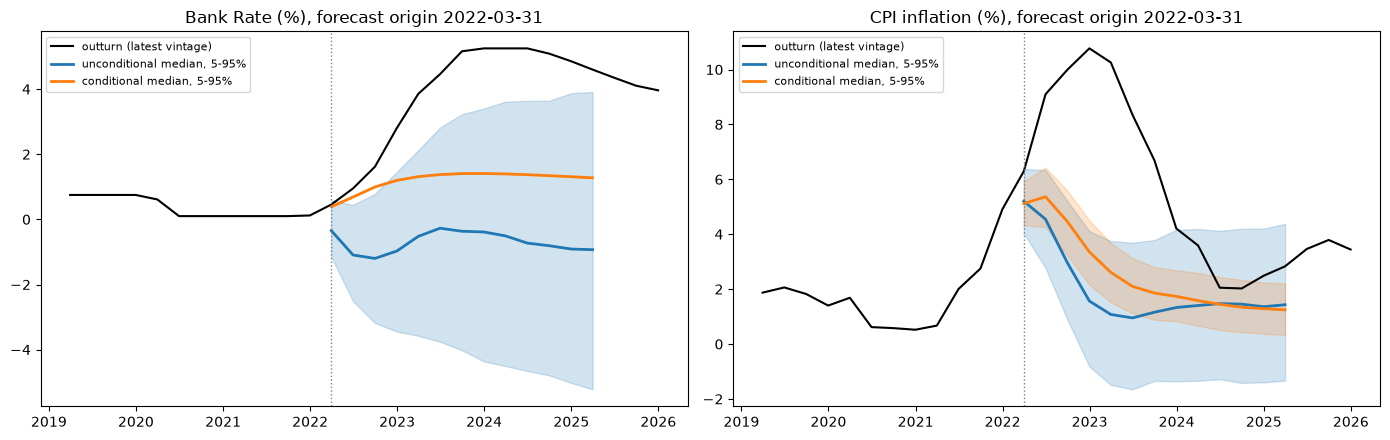

In [69]:
origin = pd.Timestamp("2022-03-31")
latest_outturns = compass_data.outturns[compass_data.outturns["vintage_date"] == compass_data.outturns["vintage_date"].max()]
panels = [("rga", "levels", 1, "Bank Rate (%)"), ("cpisa", "yoy", 100, "CPI inflation (%)")]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (var, metric, scale, title) in zip(axes, panels):
    hist = latest_outturns.query("variable == @var and metric == @metric and date >= '2019-01-01'")
    ax.plot(hist["date"], hist["value"] * scale, color="black", lw=1.5, label="outturn (latest vintage)")
    for quantiles, colour, name in [
        (compass_quantiles, "tab:blue", "unconditional"),
        (compass_quantiles_cond, "tab:orange", "conditional"),
    ]:
        q = quantiles.query("variable == @var and vintage_date == @origin")
        w = q.pivot_table(index="date", columns="quantile", values="value") * scale
        ax.fill_between(w.index, w[0.05], w[0.95], color=colour, alpha=0.2)
        ax.plot(w.index, w[0.5], color=colour, lw=2, label=f"{name} median, 5-95%")
    ax.axvline(origin, color="grey", ls=":", lw=1)
    ax.set_title(f"{title}, forecast origin {origin:%Y-%m-%d}")
    ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

### Do the CPI inflation forecasts look reasonable?

Before evaluating densities, check the centre of the forecasts. The point forecast of each BVAR is the median of its predictive density. The MPR forecasts in the same vintages are the reference: they are CPI index levels, so `ForecastData` converts them to four-quarter inflation. The hedgehog charts draw every vintage's forecast path from its starting point, against the outturns: unconditional BVAR, conditional BVAR, then MPR. The table gives the RMSE by horizon on the forecast origins all three share, and each BVAR's RMSE relative to the MPR.

                   nunique        min        max
source                                          
bvar_compass            45 2015-03-31 2026-03-31
bvar_compass_cond       45 2015-03-31 2026-03-31
mpr                     45 2015-03-31 2026-03-31


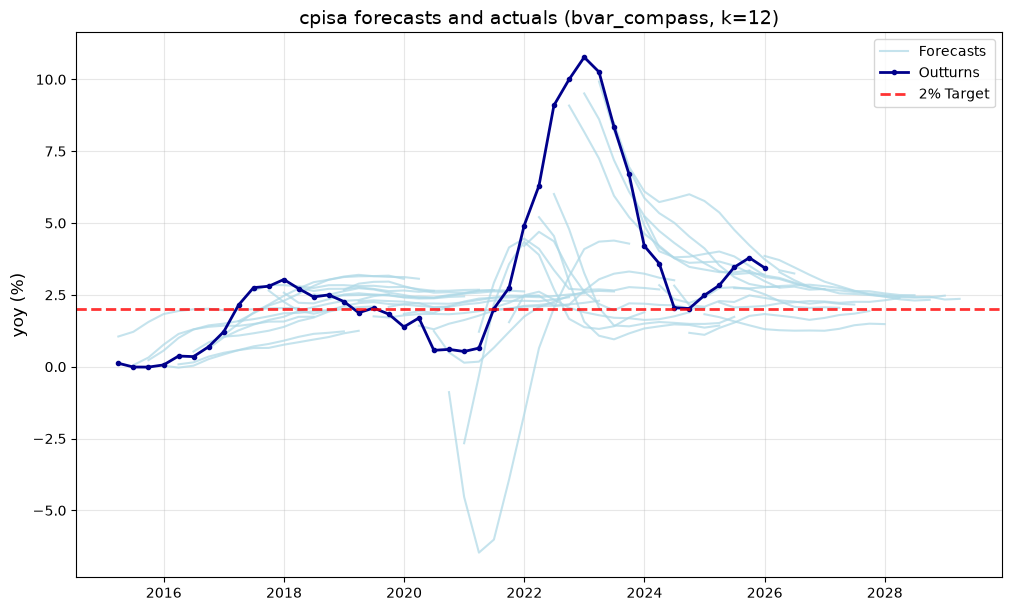

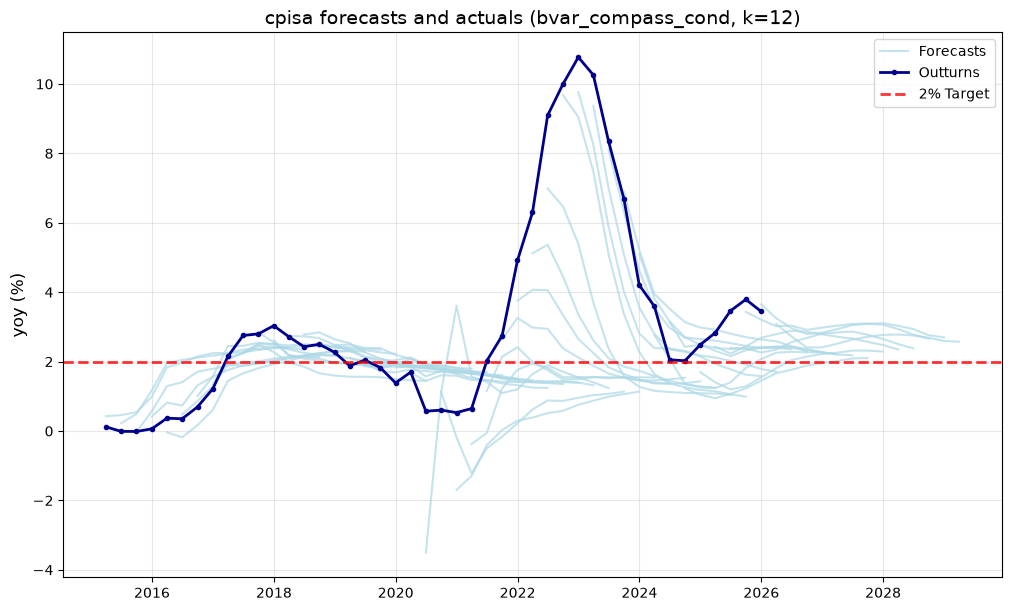

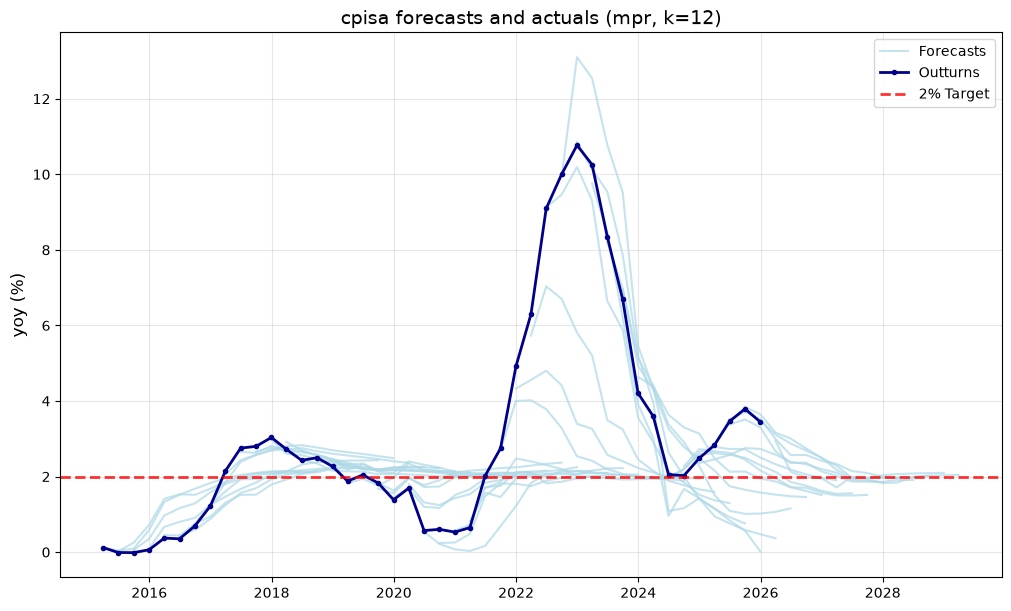

In [70]:
all_quantiles = pd.concat([compass_quantiles, compass_quantiles_cond], ignore_index=True)
cpi_q = all_quantiles[(all_quantiles["variable"] == "cpisa") & (all_quantiles["metric"] == "yoy")]
bvar_points = cpi_q[np.isclose(cpi_q["quantile"], 0.5)].drop(columns="quantile")
BVARS = ["bvar_compass", "bvar_compass_cond"]

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*has no 'metric' column")
    cpi_eval = fe.ForecastData(outturns_data=compass_outturns[compass_outturns["variable"] == "cpisa"])
    cpi_eval.add_forecasts(bvar_points)
    cpi_eval.add_forecasts(mpr[mpr["variable"] == "cpisa"], metric="levels")

print(cpi_eval.forecasts.query("metric == 'yoy'").groupby("source")["vintage_date"].agg(["nunique", "min", "max"]))
for source in [*BVARS, "mpr"]:
    cpi_eval.plot_hedgehog("cpisa", source, "yoy", convert_to_percentage=True)

In [71]:
acc = fe.compute_accuracy_statistics(cpi_eval, variable="cpisa").to_df().query("metric == 'yoy'")
rmse = acc.pivot_table(index="horizon", columns="source", values="rmse")[[*BVARS, "mpr"]] * 100  # percentage points
for source in BVARS:
    rmse[f"{source} / mpr"] = rmse[source] / rmse["mpr"]
rmse["n_origins"] = acc.groupby("horizon")["n_observations"].min()
rmse.round(2)

source,bvar_compass,bvar_compass_cond,mpr,bvar_compass / mpr,bvar_compass_cond / mpr,n_origins
horizon,,,,,,
0,0.90,0.95,0.20,4.51,4.77,44
1,1.58,1.23,0.65,2.44,1.90,43
2,2.38,1.96,1.17,2.04,1.68,42
3,3.01,2.57,1.78,1.69,1.44,41
4,3.25,3.03,2.40,1.35,1.26,40
5,3.33,3.28,2.80,1.19,1.17,39
6,3.28,3.43,3.06,1.07,1.12,38
7,3.23,3.49,3.18,1.01,1.10,37
8,3.16,3.52,3.27,0.97,1.08,36


### Notes before the density evaluation

- **What each source knows.** The unconditional BVAR conditions on nothing. The conditional BVAR knows the MPR's assumptions for rates, sterling, fiscal policy and the world, but not the staff's judgement on UK activity or CPI. The MPR has both, so it is a reference, not a like-for-like competitor.
- **Point forecast.** The median of each predictive density. `ForecastBVAR` reports the mean as its own point forecast, which is close for near-symmetric densities.
- **Outturns.** The forecasts are scored against outturns 12 revisions after release, or the latest available for recent quarters. CPI is rarely revised.
- **Sample.** 45 origins at horizon 0, fewer at longer horizons, because targets after 2025Q4 are not yet published. The 2021-2023 inflation surge dominates the errors at every horizon.

### Density evaluation: unconditional and conditional BVAR

The CPI inflation quantiles of both BVARs go into one `DensityForecastData` and are fitted with a normal, as the MTP does for its BVAR. Everything is scored against the latest outturn vintage (`k="latest"`), on the forecast origins both BVARs share (`same_date_range=True`, the default). The MPR forecasts are points, so they are not included. Neither BVAR is treated as the benchmark: the charts show both, side by side or on the same axes. PIT charts show horizons 0, 4, 8 and 12.

In [72]:
SCHEMA = ["date", "vintage_date", "variable", "source", "frequency", "forecast_horizon", "quantile", "value", "metric"]
HORIZONS = [0, 4, 8, 12]

compass_density = cpi_q[SCHEMA].astype({"quantile": float, "value": float, "forecast_horizon": int})
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="Outturns input has no 'metric' column")
    compass_cpi = fe.DensityForecastData(
        outturns_data=compass_outturns[compass_outturns["variable"] == "cpisa"], forecasts_data=compass_density
    )
fitted_compass = compass_cpi.fit_parametric_density("normal")
print(fitted_compass.diagnostics.groupby("source")["relative_error"].describe().round(4))

                   count    mean     std     min     25%     50%     75%     max
source                                                                          
bvar_compass       585.0  0.0503  0.0249  0.0156  0.0340  0.0451  0.0596  0.2426
bvar_compass_cond  585.0  0.0527  0.0321  0.0162  0.0353  0.0445  0.0601  0.3230


\\MAFP-NWSRV\DATA\Users\333415\Repos\forecast_evaluation\src\forecast_evaluation\data\DensityForecastData.py:610: UserWarning: Fitted normal quantiles differ from the stored quantiles by more than 0.05 x the fitted interquartile range for 462 of 1170 densities (largest 0.323); see FittedDensityForecasts.diagnostics.
  return fit_quantile_densities(


#### Calibration

The normal misses some stored quantiles by more than 5% of the interquartile range, which points to skew in the predictive draws. It is kept here for comparability with the MTP; `"skew_t"` is the alternative.

PIT histograms with 95% binomial bands, and PIT ECDFs with Rossi-Sekhposyan 5% bands, which allow for the serial correlation of overlapping multi-step forecasts.

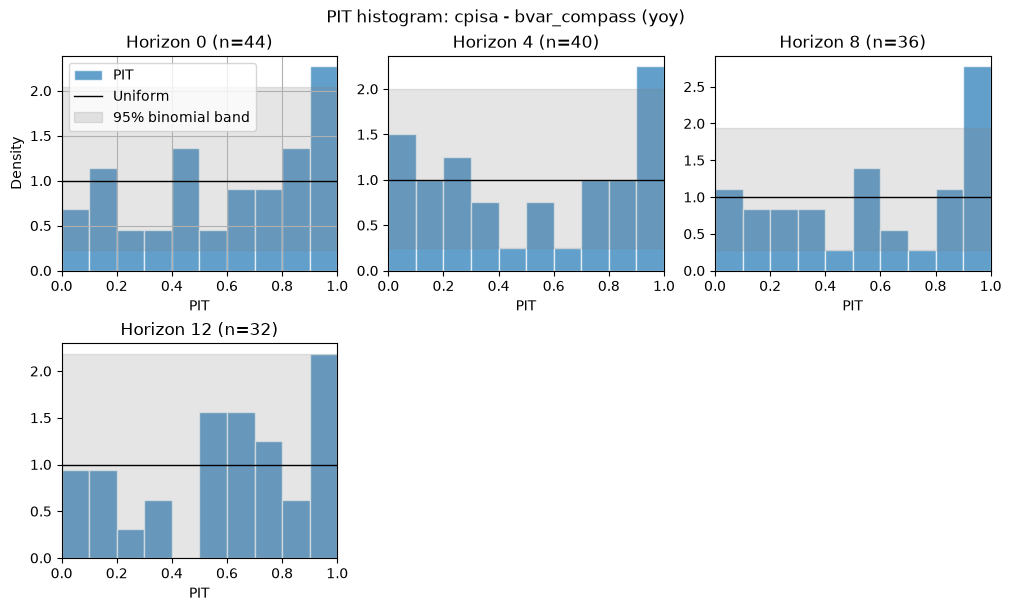

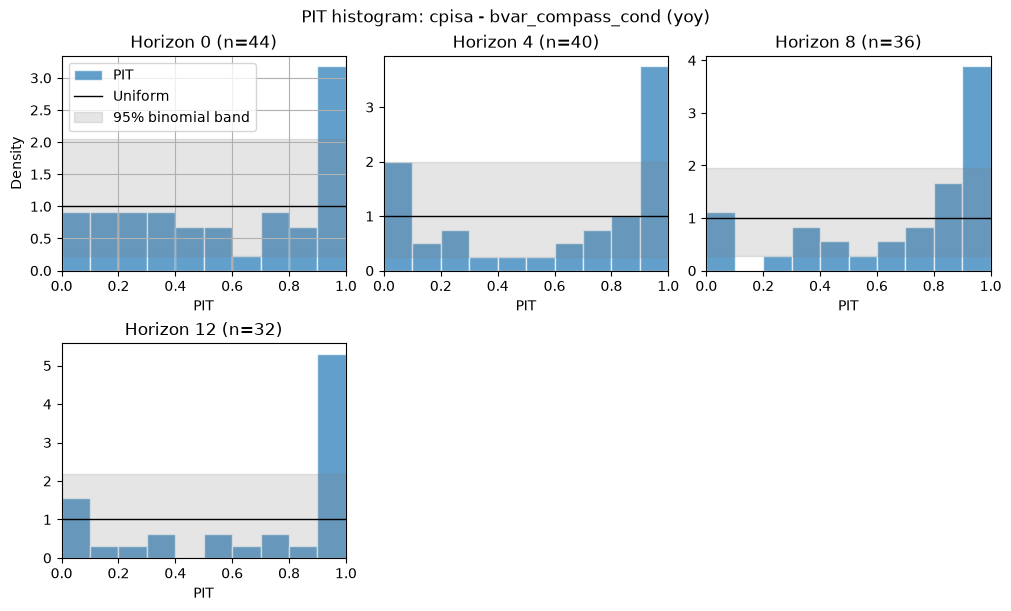

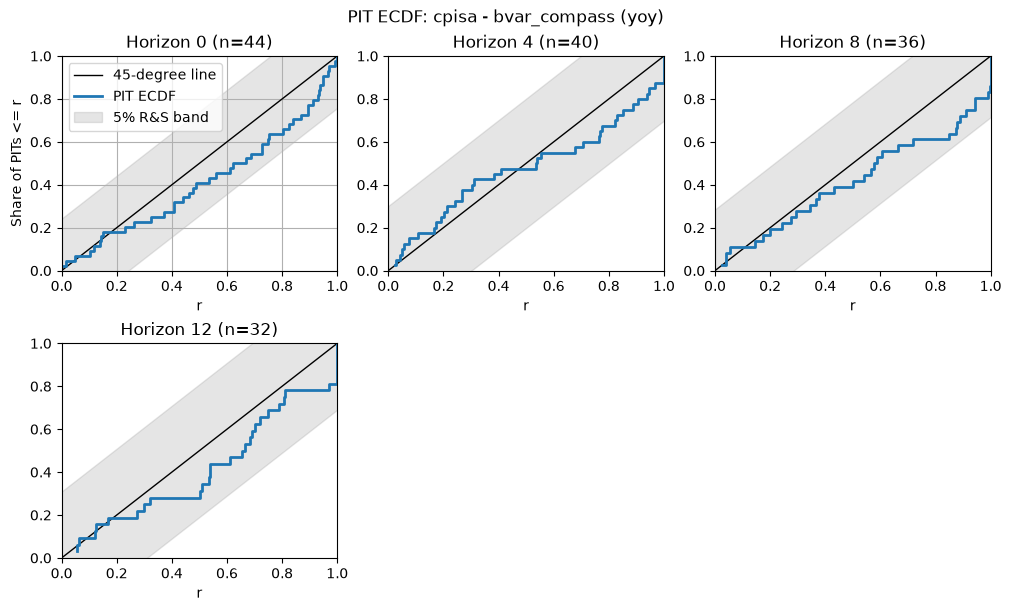

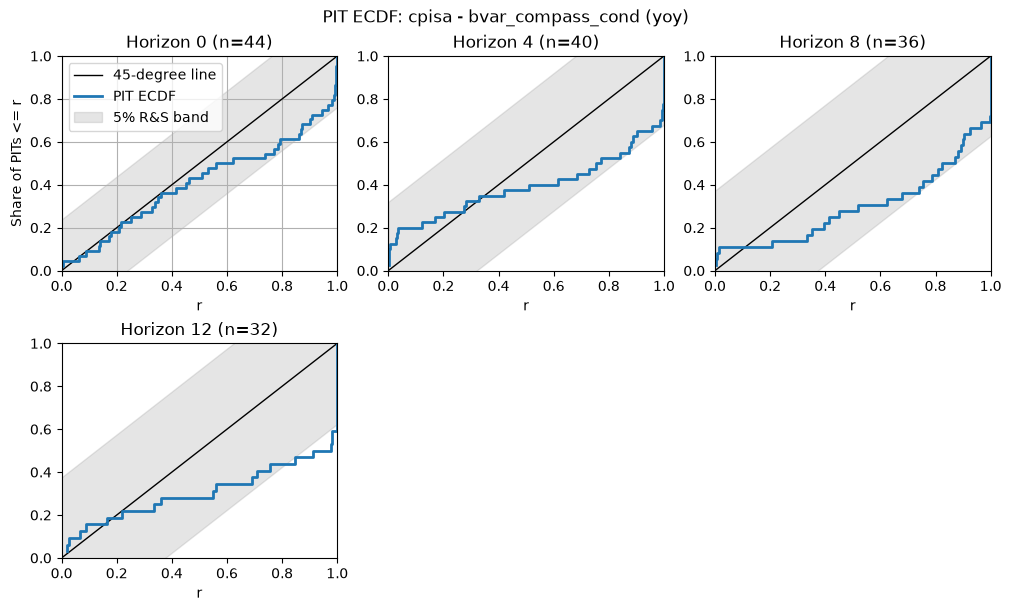

In [73]:
pit_compass = fe.compute_pit(fitted_compass, k="latest")
rs_compass = fe.rossi_sekhposyan_test(fitted_compass, k="latest", seed=0)
for source in BVARS:
    pit_compass.plot(source=source, horizons=HORIZONS)
for source in BVARS:
    pit_compass.plot(kind="ecdf", source=source, horizons=HORIZONS, rs_result=rs_compass)

Knüppel and Mitchell-Weale p-values by horizon (no plot is built in), followed by the full table. Galvão-Mantoan-Mitchell (GMM) tests the whole path of horizons jointly, on the origins that have all 13 horizons. It reports Kolmogorov-Smirnov and Cramér-von Mises statistics against 5% bootstrap critical values, so a statistic above its critical value rejects calibration.

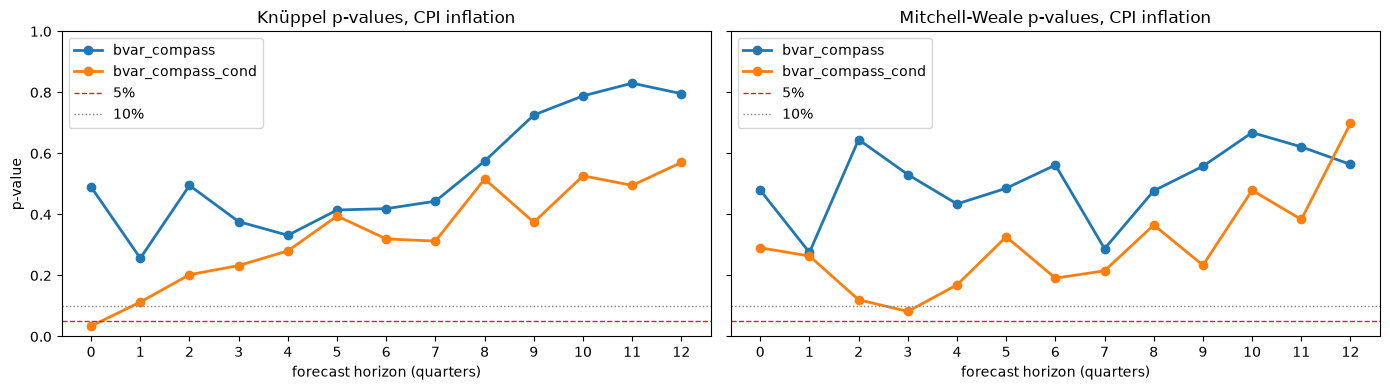

In [74]:
knuppel_compass = fe.knuppel_test(fitted_compass, k="latest").to_df()
mw_compass = fe.mitchell_weale_test(fitted_compass, k="latest").to_df()

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (df, test) in zip(axes, [(knuppel_compass, "Knüppel"), (mw_compass, "Mitchell-Weale")]):
    for source in BVARS:
        s = df[df["unique_id"] == source].sort_values("horizon")
        ax.plot(s["horizon"], s["p_value"], "o-", label=source)
    ax.axhline(0.05, color="tab:red", ls="--", lw=1, label="5%")
    ax.axhline(0.10, color="grey", ls=":", lw=1, label="10%")
    ax.set(xlabel="forecast horizon (quarters)", ylim=(0, 1), title=f"{test} p-values, CPI inflation")
    ax.set_xticks(range(COMPASS_STEPS))
    ax.legend()
axes[0].set_ylabel("p-value")
fig.tight_layout()
plt.show()

In [75]:
gmm_compass = fe.galvao_mantoan_mitchell_test(fitted_compass, k="latest", seed=0).to_df().set_index("unique_id")


def calibration_table(source):
    by_h = lambda df: df[df["unique_id"] == source].set_index("horizon").sort_index()
    k, mw, gmm = by_h(knuppel_compass), by_h(mw_compass), gmm_compass.loc[source]
    table = pd.DataFrame(
        {
            ("Knüppel", "stat"): k["stat"],
            ("Knüppel", "p-value"): k["p_value"],
            ("Mitchell-Weale", "stat"): mw["stat"],
            ("Mitchell-Weale", "p-value"): mw["p_value"],
            ("", "n"): k["n_observations"],
        }
    )
    table.index = table.index.astype(str)
    joint = pd.DataFrame(
        {
            ("GMM (joint)", "KS stat"): gmm["ks_stat"],
            ("GMM (joint)", "KS crit."): gmm["ks_cv"],
            ("GMM (joint)", "CvM stat"): gmm["cvm_stat"],
            ("GMM (joint)", "CvM crit."): gmm["cvm_cv"],
            ("", "n"): gmm["n_observations"],
        },
        index=[f"0-{COMPASS_STEPS - 1} joint"],
    )
    return pd.concat([table, joint])


calibration = pd.concat({source: calibration_table(source) for source in BVARS}, names=["source", "horizon"])
calibration.round(3).fillna("")

Knüppel         Mitchell-Weale             GMM (joint)                            
                                stat p-value           stat p-value   n     KS stat KS crit. CvM stat CvM crit.
source            horizon                                                                                      
bvar_compass      0            3.422    0.49          4.504   0.479  44                                        
                  1            5.315   0.256           6.33   0.275  43                                        
                  2            3.388   0.495          3.356   0.645  42                                        
                  3            4.225   0.376          4.131   0.531  41                                        
                  4            4.593   0.332          4.851   0.434  40                                        
                  5            3.937   0.415          4.456   0.486  39                                        
                  6            3.906   0.419          3.914   0.562  38                                        
                  7            3.732   0.443          6.196   0.288  37                                        
                  8            2.901   0.575          4.518   0.477  36                                        
                  9            2.054   0.726          3.941   0.558  35                                        
                  10           1.712   0.788          3.207   0.668  34                                        
                  11            1.48    0.83          3.513   0.621  33                                        
                  12           1.673   0.796            3.9   0.564  32                                        
                  0-12 joint                                         32       1.609    2.058     0.65     2.114
bvar_compass_cond 0           10.392   0.034          6.164   0.291  44                                        
                  1            7.474   0.113          6.463   0.264  43                                        
                  2            5.954   0.203          8.731    0.12  42                                        
                  3            5.584   0.232          9.765   0.082  41                                        
                  4            5.066   0.281          7.772   0.169  40                                        
                  5            4.083   0.395          5.795   0.327  39                                        
                  6            4.698    0.32          7.421   0.191  38                                        
                  7            4.761   0.313          7.073   0.215  37                                        
                  8            3.256   0.516          5.432   0.365  36                                        
                  9            4.241   0.374           6.83   0.234  35                                        
                  10            3.19   0.527          4.506   0.479  34                                        
                  11           3.387   0.495          5.273   0.383  33                                        
                  12           2.926    0.57           3.01   0.698  32                                        
                  0-12 joint                                         32       2.693    1.993    2.188     2.036

#### Sharpness

The median width of three intervals by horizon, with a band of one standard deviation, for both BVARs on the same axes: the lower tail (5th to 25th percentile), the central 50% (25th to 75th) and the upper tail (75th to 95th). The fit is normal, so the two tails have the same width. Values are in inflation fractions (0.01 is one percentage point). The conditional BVAR treats its assumptions as known, so it should be sharper. Calibration and CRPS show whether that sharpness is earned.

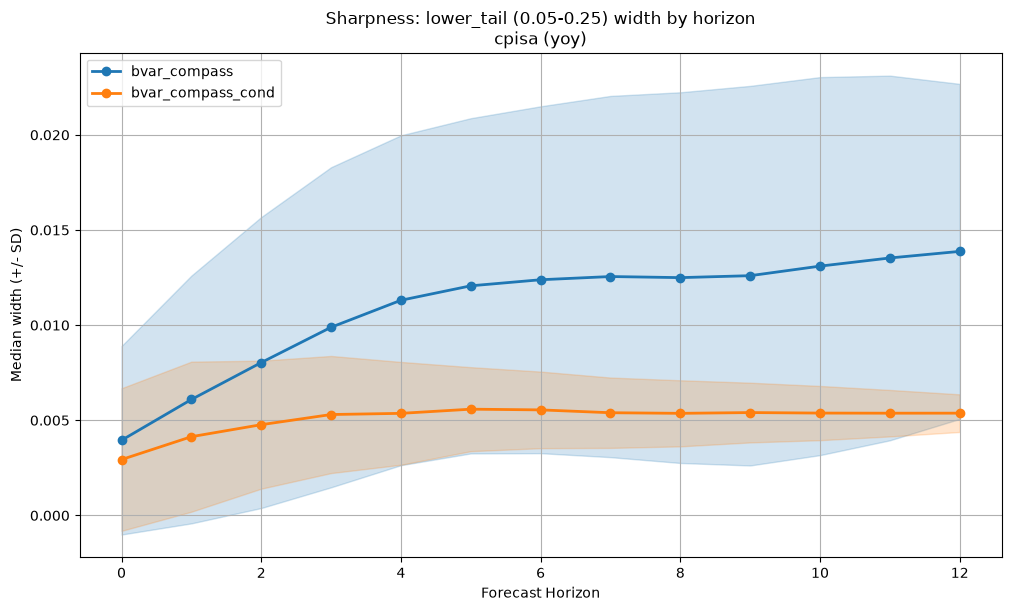

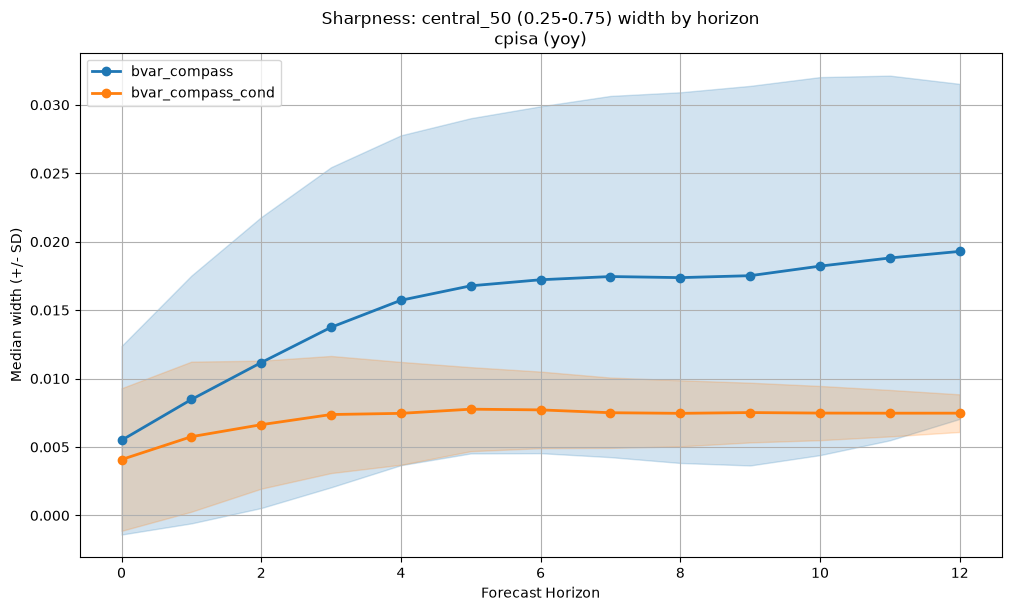

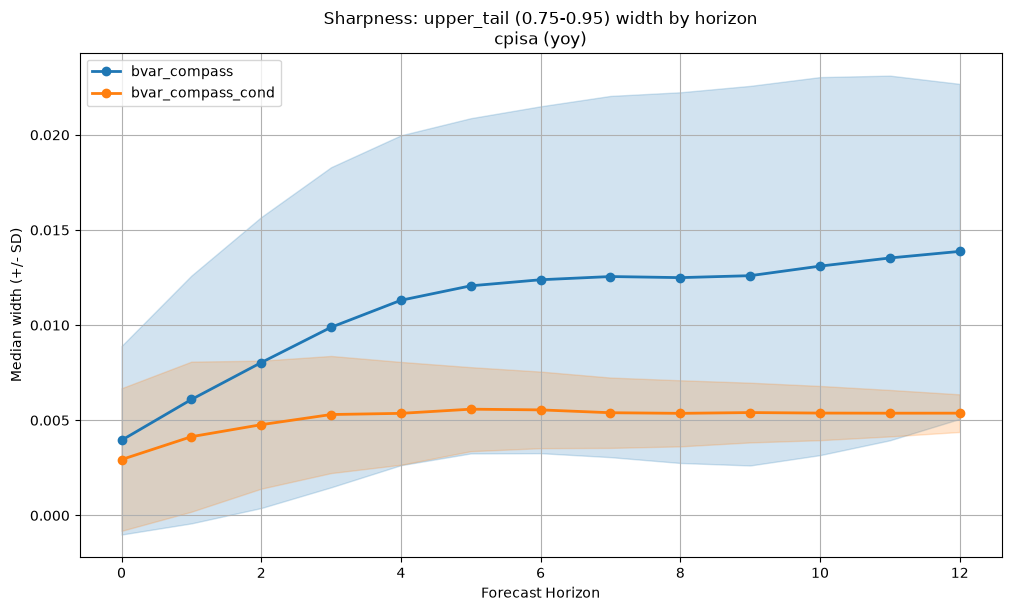

In [76]:
sharpness_compass = fe.sharpness_analysis(fitted_compass, k="latest")
for interval in ["lower_tail", "central_50", "upper_tail"]:
    sharpness_compass.plot(interval=interval)

#### CRPS

The mean CRPS by horizon, and the mean right-tail weighted CRPS (weight $\tau^2$, emphasising upside inflation risk), as in the MTP table, for both BVARs on the same axes. Lower is better. Both are in inflation fractions. For a point forecast the CRPS reduces to the absolute error, so the mean CRPS is comparable with the MPR's mean absolute error (`mean_abs_error` in the accuracy statistics above).

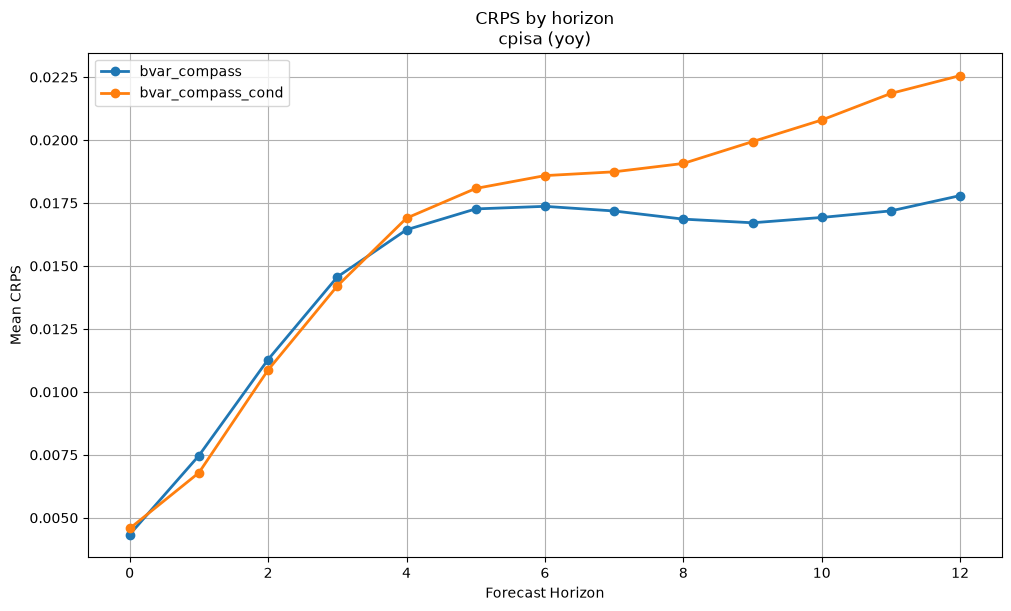

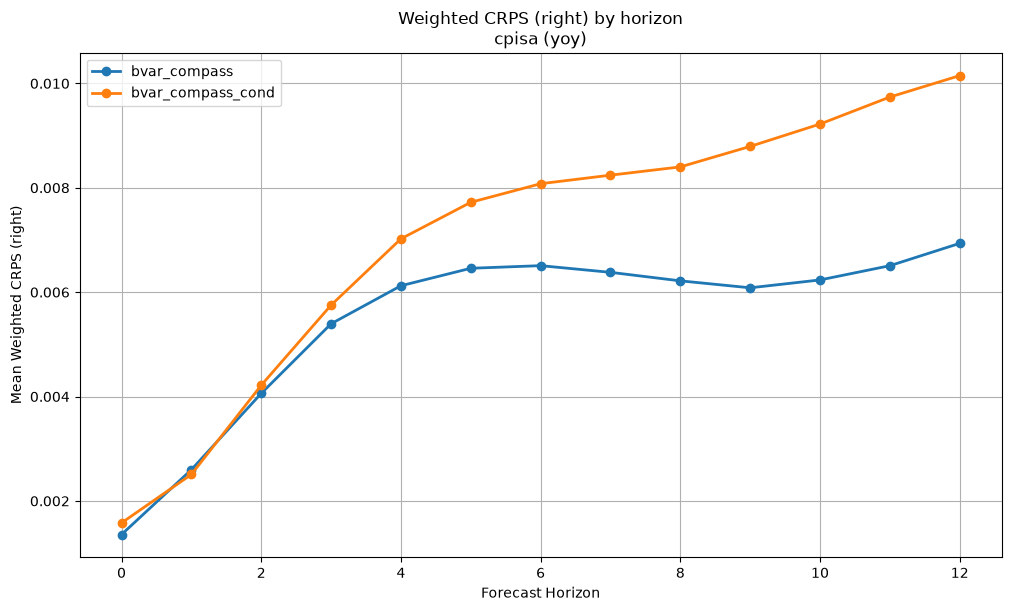

In [77]:
crps_compass = fe.crps_analysis(fitted_compass, k="latest")
crps_right_compass = fe.crps_analysis(fitted_compass, k="latest", weight="right")
crps_compass.plot()
crps_right_compass.plot()